# Open-set re-identification

Given an observation, a sequence of photographs of one animal, decide whether the animal is
already in the gallery, and if so which individual it is. Seven steps are compared. Each adds one
part to the step before it:

1. MiewID zero-shot, the plain mean of the image scores
2. \+ MiewID fine-tuning
3. \+ relevance weighting
4. \+ ALIKED/LightGlue rerank, scored by the raw match count
5. \+ RANSAC verification: the same pairs, scored by the RANSAC inliers
6. \+ logistic knownness
7. \+ MAP open-set decision

Steps 1-5 threshold the top retrieval score. Step 6 thresholds a knownness probability instead.
Step 7 replaces the threshold with the MAP decision rule.

**Evaluation.** One identity-disjoint 70/10/20 split. 
Two gallery policies are reported: a **sparse gallery** with one observation per individual, and a **rich gallery** with every observation except the query's own.

The validation split has two roles. Its queries are divided, at the observation level, into a
part that *fits* the relevance, knownness and calibration models, and a part that *scores* them.
The scoring part stands in for the test split wherever a threshold must be chosen. Both parts
hold the same individuals: what is held out is the evidence.

## Settings

In [1]:
import tomllib
from pathlib import Path

ROOT = Path.cwd().parent
CONFIG = tomllib.loads((ROOT / "config.toml").read_text())

# Relative paths in config.toml start at the folder that holds it.
DATA_ROOT = ROOT / Path(CONFIG["data_root"]).expanduser()
SEGMENTED_COMPRESSED = DATA_ROOT / "segmented_compressed"
CACHE_DIR = ROOT / Path(CONFIG["cache_dir"]).expanduser()
EMBEDDINGS = CACHE_DIR / "embeddings"
FIGURE_DIR = ROOT / Path(CONFIG["output_dir"]).expanduser() / "figures"
for path in (SEGMENTED_COMPRESSED, EMBEDDINGS):
    assert path.exists(), f"Not found: {path}. Check the paths in {ROOT / 'config.toml'}."
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import matplotlib.pyplot as plt

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#6E6E6E"]
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True, "axes.unicode_minus": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "figure.figsize": (7.0, 4.2), "figure.dpi": 130,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.04,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#D8DEE9", "grid.linewidth": 0.6, "grid.alpha": 0.45,
    "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "legend.frameon": False,
    "lines.linewidth": 2.0, "lines.markersize": 5,
})

## Data and split

The individuals are split 70/10/20 into training, validation and test, stratified by their
number of observations. 

In [3]:
import json
import re

import numpy as np
import pandas as pd
from itables import init_notebook_mode, show
from sklearn.model_selection import train_test_split

init_notebook_mode(all_interactive=True)  # every DataFrame shown from here on is interactive

SEED = 42
# 'SH024_002_007_det0_cropped.jpg' -> individual 'SH024', observation number '002'. The photo number
# and SAM 3's suffixes (_det<n>, _segmented, _mask, _cropped, _annotated) are optional.
PHOTO_NAME = re.compile(r"^(?P<identity>SH\d+)_(?P<number>\d+)(?:_\d+)?"
                        r"(?:_det\d+|_segmented|_mask|_cropped|_annotated)*(?:\.[^.]+)?$")
CROP = re.compile(r"^(?P<photograph>.+)_det(?P<detection>\d+)_cropped\.jpg$")
TRAIN_FRACTION, VALIDATION_FRACTION = 0.70, 0.10  # the test split takes the remaining 20%
SPLITS = ("train", "validation", "test")

# The SAM 3 score of every crop. The paper's crops come from an earlier run of the same model and
# settings, which wrote summary.json; 1_segment_images.ipynb records its crops in detections.json.
# Both are read, so crops from the two runs can sit side by side; detections.json wins a tie.
crop_scores = {}
summary = DATA_ROOT / "summary.json"
if summary.exists():
    for record in json.loads(summary.read_text())["results"]:
        stem = Path(record["image_key"]).stem
        for index, score in enumerate(record.get("scores") or []):
            crop_scores[f"{stem}_det{index}_cropped.jpg"] = float(score)
detections = DATA_ROOT / "detections.json"
if detections.exists():
    crop_scores.update({record["name"]: float(record["score"])
                        for record in json.loads(detections.read_text())})

# One crop per photograph: the SAM 3 detection with the highest score. SAM 3 lists its detections
# in the order of its internal queries, not by score, so _det0 is not always the best crop. Ties go
# to the lower detection number. A file that is not a SAM 3 crop is kept as it is.
crop_files = pd.Series(sorted(path.name for path in SEGMENTED_COMPRESSED.glob("*.jpg")))
detected = crop_files.str.extract(CROP).assign(name=crop_files)
detected["detection"] = pd.to_numeric(detected["detection"])
detected["score"] = detected["name"].map(crop_scores)
several = detected.groupby("photograph")["name"].transform("size") > 1
assert detected.loc[several, "score"].notna().all(), "A photograph with several crops has no SAM 3 score"
best = (detected.dropna(subset=["photograph"])
        .sort_values(["photograph", "score", "detection"], ascending=[True, False, True])
        .drop_duplicates("photograph"))
best_crops = sorted(best["name"].tolist() + detected.loc[detected["photograph"].isna(), "name"].tolist())

# The image table: one row per crop, sorted by name, with its individual and its observation.
names = pd.Series(best_crops)
parts = names.str.extract(PHOTO_NAME)
skipped = names[parts["identity"].isna()].tolist()
if skipped:
    print(f"Skipped {len(skipped)} files whose names do not follow the "
          f"SH<identity>_<observation>_<photo> convention, e.g. {skipped[:3]}")
crops = (pd.DataFrame({"name": names, "identity": parts["identity"],
                       "observation": parts["identity"] + "_" + parts["number"]})
         .dropna().reset_index(drop=True))

# Every photograph of an individual goes to the same split, so the split is drawn over individuals.
# It is stratified by their number of observations, in bins: 1, 2, 3, 4, 5-9 and 10 or more. A
# stratum needs at least two individuals, and most counts above 10 have only one.
observation_count = crops.groupby("identity")["observation"].nunique()
stratum = pd.Series(np.digitize(observation_count, [2, 3, 4, 5, 10]), index=observation_count.index)
# First 70% for training, then the other 30% divided 1:2 into validation and test.
train_ids, rest = train_test_split(observation_count.index, train_size=TRAIN_FRACTION,
                                   stratify=stratum, random_state=SEED)
validation_ids, test_ids = train_test_split(rest, train_size=VALIDATION_FRACTION / (1 - TRAIN_FRACTION),
                                            stratify=stratum[rest], random_state=SEED)
split_by_identity = {**dict.fromkeys(train_ids, "train"), **dict.fromkeys(validation_ids, "validation"),
            **dict.fromkeys(test_ids, "test")}
images = crops.assign(split=crops["identity"].map(split_by_identity))
train, validation, test = (images[images["split"] == split].reset_index(drop=True)
                           for split in SPLITS)
for name, frame in (("train", train), ("validation", validation), ("test", test)):
    print(f"{name:10s} {frame['identity'].nunique():4d} individuals "
          f"{frame['observation'].nunique():5d} observations {len(frame):6d} photographs")
show(images, scrollY="400px", scroller=True, maxBytes=0, showIndex=False)

train       331 individuals  1723 observations  21029 photographs
validation   47 individuals   237 observations   2812 photographs
test         96 individuals   528 observations   6659 photographs


The embeddings: MiewID zero-shot, MiewID fine-tuned on the training split, and DINOv3. 

In [4]:
# The fine-tuned embedding cache is named after the training run, the folder of the checkpoint.
FINETUNED_RUN = (ROOT / Path(CONFIG["miewid_checkpoint"]).expanduser()).parent.name


def read_embeddings(path):
    """An embedding cache: a dict with the row of each image name, and the matrix of vectors."""
    if not Path(path).exists():
        raise FileNotFoundError(f"No embedding cache at {path}. Run 3_extract_embeddings.ipynb.")
    with np.load(path) as stored:
        names = stored["names"].tolist()
        vectors = stored["embeddings"]
    return {"path": Path(path), "row": {name: row for row, name in enumerate(names)}, "vectors": vectors}


EMB = {"miewid": read_embeddings(EMBEDDINGS / "miewid_msv3.npz"),
       "miewid_finetuned": read_embeddings(EMBEDDINGS / f"miewid_msv3_finetuned_{FINETUNED_RUN}.npz"),
       "dinov3": read_embeddings(EMBEDDINGS / "dinov3_vitl16_cls.npz")}

## Query batches

**The calibration split.** The validation queries are divided into a fit part and a scoring
part. The division is *within* each individual, so both parts see the same animals. An individual with one
observation is only an unknown query. Its observation goes to the scoring side with probability
0.35.

**Galleries and masks.** The gallery of a batch is its whole evaluation split. A mask removes what
each query must not see: its own observation (known queries), or its whole individual (unknown
queries), and under the sparse policy all but one observation of each other individual.

In [5]:
from sklearn.preprocessing import normalize

def take(cache, names, normalise=True):
    """The vectors of the named images, in order, scaled to length 1 unless normalise=False.

    Fails on a missing or non-finite vector: a NaN would otherwise surface much later, as a
    metric that refuses an infinite score.
    """
    missing = [name for name in dict.fromkeys(names) if name not in cache["row"]]
    if missing:
        raise FileNotFoundError(f"{len(missing)} images are missing from {cache['path']}, "
                                f"e.g. {missing[:3]}. Run 3_extract_embeddings.ipynb.")
    vectors = cache["vectors"][[cache["row"][name] for name in names]]
    corrupt = [names[row] for row in np.flatnonzero(~np.isfinite(vectors).all(axis=1))]
    if corrupt:
        raise ValueError(f"Non-finite embeddings in {cache['path']}, e.g. {corrupt[:3]}")
    if not normalise:
        return vectors
    return normalize(vectors, norm="l2", axis=1)


def observation_groups(images):
    """The image rows of each observation, the individual of each observation, and its name."""
    grouped = images.reset_index(drop=True).groupby("observation", sort=False)
    first = grouped["identity"].first()
    return list(grouped.indices.values()), first.to_numpy(str), first.index.to_numpy(str)


def make_gallery(images, name):
    """A gallery: its images, and their grouping into observations."""
    images = images.reset_index(drop=True)
    groups, identities, observations = observation_groups(images)
    return {"name": name, "images": images, "image_groups": groups,
            "observation_identities": identities, "observations": observations}


def known_query_identities(images):
    """The individuals of a split with two or more observations: they give known queries."""
    counts = images.groupby("identity")["observation"].nunique()
    return set(counts.index[counts >= 2])

CALIBRATION_SCORE_FRACTION = 0.35  # of the validation queries: 35% score the models, 65% fit them

# The validation queries divided into a fit part and a scoring part, in both roles.
rng = np.random.default_rng(SEED)
singleton_rng = np.random.default_rng(SEED + 1)
fit, score = [], []
for _, group in validation.groupby("identity", sort=True):
    observations = group["observation"].unique()
    rng.shuffle(observations)
    if len(observations) <= 1:
        (score if singleton_rng.random() < CALIBRATION_SCORE_FRACTION else fit).extend(observations)
        continue
    n_score = min(max(1, round(len(observations) * CALIBRATION_SCORE_FRACTION)), len(observations) - 1)
    score.extend(observations[:n_score])
    fit.extend(observations[n_score:])




is_known = validation["identity"].isin(known_query_identities(validation))
in_fit, in_score = validation["observation"].isin(fit), validation["observation"].isin(score)
QUERY_SETS = {"fit_known": validation[is_known & in_fit].reset_index(drop=True),
              "fit_unknown": validation[in_fit].reset_index(drop=True),
              "score_known": validation[is_known & in_score].reset_index(drop=True),
              "score_unknown": validation[in_score].reset_index(drop=True),
              "test_known": test[test["identity"].isin(known_query_identities(test))].reset_index(drop=True),
              "test_unknown": test}

GALLERIES = {"validation": make_gallery(validation, "validation"), "test": make_gallery(test, "test")}

GALLERY_BY_QUERY_SET = {name: "test" if name.startswith("test") else "validation" for name in QUERY_SETS}

SIMILARITY, FEATURES = {}, {}

for name, queries in QUERY_SETS.items():
    query_names = queries["name"].tolist()
    gallery_names = GALLERIES[GALLERY_BY_QUERY_SET[name]]["images"]["name"].tolist()
    SIMILARITY[name] = {backbone: take(EMB[backbone], query_names) @ take(EMB[backbone], gallery_names).T
                        for backbone in ("miewid", "miewid_finetuned")}
    FEATURES[name] = take(EMB["dinov3"], query_names)

In [6]:
from hashlib import blake2b

GALLERY_DRAWS = 5  # independent draws of the sparse gallery; the rich gallery has one
SPARSE_GALLERY = "one_observation_per_individual"
RICH_GALLERY = "all_except_query"

GALLERY_POLICIES = {SPARSE_GALLERY: "Sparse gallery (one observation per individual)",
                    RICH_GALLERY: "Rich gallery (all observations except the query)"}


def gallery_valid_mask(query_observations, gallery_identities, gallery_observations, policy, seed,
                       query_identities=None):
    """Which gallery entries each query may be matched against.
    """
    valid = query_observations[:, None] != gallery_observations[None, :]
    if query_identities is not None:
        valid &= query_identities[:, None] != gallery_identities[None, :]
    if policy == RICH_GALLERY:
        return valid
    sparse = np.zeros_like(valid)
    for identity in np.unique(gallery_identities):
        belongs = gallery_identities == identity
        for row, query_observation in enumerate(query_observations):
            eligible = valid[row] & belongs
            if not eligible.any():
                continue
            observations = np.unique(gallery_observations[eligible])
            # A reproducible pseudo-random choice that does not depend on Python's hash seed.
            digest = blake2b(f"{seed}|{query_observation}|{identity}".encode(), digest_size=8).digest()
            chosen = observations[int.from_bytes(digest, "little") % len(observations)]
            sparse[row] |= eligible & (gallery_observations == chosen)
    return sparse


def make_batch(images, gallery, policy, seed, unknown, similarity, relevance_features,
               unit="observation"):
    """One batch of queries searched against one gallery, with its gallery-policy masks.

    A query row is an observation, whose photographs are pooled, or a single image (unit="image").
    The mask still uses the real observation of each image, so an image query also drops its own
    observation and draws the same sparse gallery.

    `similarity` maps a backbone to the query-image by gallery-image cosine matrix, and
    `relevance_features` holds the DINOv3 vector of each query image, for step 3.

    Unknown queries get the same gallery policy as known ones, and their masks also hide their
    own individual. Scores are maxima over gallery images, so a wider gallery for unknown queries
    would raise their scores.
    """
    images = images.reset_index(drop=True)
    if unit == "observation":
        image_groups, identities, row_observations = observation_groups(images)
    else:
        image_groups = [np.array([row]) for row in range(len(images))]
        identities = images["identity"].to_numpy(str)
        row_observations = images["observation"].to_numpy(str)
    image_mask = gallery_valid_mask(
        images["observation"].to_numpy(str), gallery["images"]["identity"].to_numpy(str),
        gallery["images"]["observation"].to_numpy(str), policy, seed,
        query_identities=images["identity"].to_numpy(str) if unknown else None)
    observation_mask = gallery_valid_mask(
        row_observations, gallery["observation_identities"], gallery["observations"], policy, seed,
        query_identities=identities if unknown else None)
    return {"images": images, "gallery": gallery, "image_groups": image_groups,
            "identities": identities, "image_mask": image_mask, "observation_mask": observation_mask,
            "similarity": similarity, "relevance_features": relevance_features}




def query_identities(rows):
    """The sorted query individuals of some result rows, in both roles."""
    return np.unique(np.concatenate([np.r_[row["known_identities"], row["unknown_identities"]]
                                     for row in rows]))


REPLICATES = [(policy, draw) for policy in GALLERY_POLICIES
              for draw in range(GALLERY_DRAWS if policy == SPARSE_GALLERY else 1)]
BATCHES = {(policy, draw): {name: make_batch(queries, GALLERIES[GALLERY_BY_QUERY_SET[name]], policy, SEED + 1000 * draw,
                             name.endswith("_unknown"), SIMILARITY[name], FEATURES[name], "observation")
            for name, queries in QUERY_SETS.items()} for policy, draw in REPLICATES}
for name, batch in BATCHES[REPLICATES[0]].items():
    print(f"{name:14s} {len(batch['image_groups']):5d} query observations, "
          f"{len(batch['images']):6d} photographs")

fit_known        142 query observations,   1648 photographs
fit_unknown      153 query observations,   1821 photographs
score_known       76 query observations,    901 photographs
score_unknown     84 query observations,    991 photographs
test_known       489 query observations,   6095 photographs
test_unknown     528 query observations,   6659 photographs


### A worked example

SH362_002: 6 photographs of SH362. As a known query, the sparse gallery keeps SH362_009 of SH362; as an unknown query, it keeps no observation of SH362.


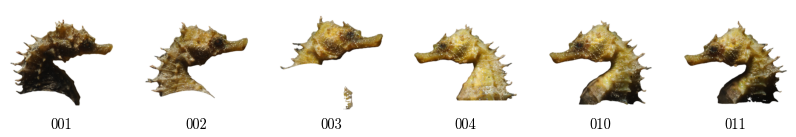

In [7]:
from PIL import Image, ImageOps

EXAMPLE_OBSERVATION = "SH362_002"  # chosen to show the steps at work, see above
CALIBRATION_BATCHES = ("fit_known", "fit_unknown", "score_known", "score_unknown")
TEST_BATCHES = ("test_known", "test_unknown")
ROLES = {"test_known": "Known query", "test_unknown": "Unknown query"}


def example_batch(name):
    """The example observation alone, as a batch of the query set `name`, first sparse draw."""
    queries = QUERY_SETS[name]
    rows = np.flatnonzero(queries["observation"].to_numpy() == EXAMPLE_OBSERVATION)
    return make_batch(queries.iloc[rows], GALLERIES["test"], SPARSE_GALLERY, SEED,
                      name.endswith("_unknown"),
                      {backbone: matrix[rows] for backbone, matrix in SIMILARITY[name].items()},
                      FEATURES[name][rows])


def show_photographs(names, titles):
    """The photographs side by side, each centred on a white square, with a title under each."""
    figure, axes = plt.subplots(1, len(names), figsize=(1.3 * len(names), 1.8), squeeze=False)
    for axis, name, title in zip(axes[0], names, titles):
        image = Image.open(SEGMENTED_COMPRESSED / name).convert("RGB")
        image = ImageOps.pad(image, (max(image.size),) * 2, color=(255, 255, 255))
        image.thumbnail((256, 256))
        axis.imshow(image)
        axis.set_axis_off()
        axis.set_title(title, fontsize=8, y=-0.2)
    plt.show()


# The sparse mask hashes the seed, the query observation and the identity, so the example sees
# the same gallery as it does inside the whole test batch.
EXAMPLE = {name: example_batch(name) for name in TEST_BATCHES}
example_calibration = {name: BATCHES[SPARSE_GALLERY, 0][name] for name in CALIBRATION_BATCHES}

known_query = EXAMPLE["test_known"]
identity = known_query["identities"][0]
gallery = known_query["gallery"]
print(f"{EXAMPLE_OBSERVATION}: {len(known_query['images'])} photographs of {identity}. "
      f"As a known query, the sparse gallery keeps "
      f"""{', '.join(gallery['observations'][known_query['observation_mask'][0]
                                            & (gallery['observation_identities'] == identity)])} """
      f"of {identity}; as an unknown query, it keeps no observation of {identity}.")
show_photographs(known_query["images"]["name"].tolist(),
                 [name.split("_")[2] for name in known_query["images"]["name"]])

## Steps 1 and 2: the global descriptor

For a query observation, we score each gallery identity by the mean, over the query's photographs, of each
photograph's best cosine to that identity's eligible gallery photographs (equation 4). The
threshold maximises the normalized accuracy (NA).

In [8]:
from sklearn.metrics import roc_auc_score, roc_curve

NEW_INDIVIDUAL = "new"

THRESHOLD_QUANTILES = np.linspace(0.0, 1.0, 51)

RELEVANCE_FLOOR = 0.02  # a photograph's weight never falls below this, so none is discarded


def identity_scores(similarity, gallery_labels, valid_mask):
    """Max-pool a query-by-gallery matrix into one score per gallery identity.

    Returns (scores, identity labels in order of first appearance). An identity scores -inf for a
    query that may see none of its gallery entries. A non-finite entry scores -inf too and can
    never win, so one corrupt embedding cannot turn its identity's score into NaN for every query.
    """
    assert valid_mask.any(axis=1).all(), "Every query needs at least one eligible gallery identity"
    similarity = np.asarray(similarity, dtype=np.float32)  # (n_queries, n_gallery)
    similarity_masked = np.where(valid_mask & np.isfinite(similarity), similarity, -np.inf)
    # One row per gallery entry, grouped by identity in order of first appearance; each group's maximum.
    by_identity = pd.DataFrame(similarity_masked.T).groupby(gallery_labels, sort=False).max()
    return np.ascontiguousarray(by_identity.to_numpy().T), by_identity.index.to_numpy(str)


def top_k_hits(score_matrix, gallery_labels, valid_mask, true_identities, k=5):
    """Whether each query's true identity is in its top k."""
    scores, labels = identity_scores(score_matrix, gallery_labels, valid_mask)
    true_columns = pd.Series(np.arange(len(labels)), index=labels)[true_identities].to_numpy()
    true_scores = scores[np.arange(len(true_columns)), true_columns]
    return np.isfinite(true_scores) & ((scores >= true_scores[:, None]).sum(axis=1) <= k)


def baks(true_identities, predicted_identities, accepted=None):
    """Balanced accuracy on known samples: recall per identity, averaged over identities.

    A known query counts only when it is accepted and gets the right identity.
    """
    if true_identities.size == 0:
        return 0.0
    hits = predicted_identities == true_identities
    if accepted is not None:
        hits = hits & accepted
    return float(pd.Series(hits).groupby(true_identities).mean().mean())


def baus(true_identities, predicted_identities):
    """Balanced accuracy on unknown samples: the rate per identity of being called new."""
    if true_identities.size == 0:
        return 0.0
    rejected = predicted_identities == NEW_INDIVIDUAL
    return float(pd.Series(rejected).groupby(true_identities).mean().mean())


def evaluate_threshold(known_scores, known_identities, known_predictions, unknown_scores,
                       unknown_identities, threshold):
    """The open-set metrics when every query scoring at least `threshold` is accepted."""
    baks_value = baks(known_identities, known_predictions, accepted=known_scores >= threshold)
    baus_value = baus(unknown_identities,
                      np.where(unknown_scores >= threshold, "accepted", NEW_INDIVIDUAL))
    # Alpha: the share of known-query individuals. Each role counts an individual once.
    known, unknown = set(known_identities), set(unknown_identities)
    total = len(known) + len(unknown)
    alpha = len(known) / total if total else float("nan")
    # Knownness AUROC: how well the score separates known queries from new individuals.
    labels = np.r_[np.ones(len(known_scores), dtype=int), np.zeros(len(unknown_scores), dtype=int)]
    auroc = (roc_auc_score(labels, np.r_[known_scores, unknown_scores])
             if len(np.unique(labels)) > 1 else float("nan"))
    return {"BAKS": baks_value, "BAUS": baus_value,
            "BRA": alpha * baks_value + (1.0 - alpha) * baus_value,  # alpha-weighted mean
            "normalized_accuracy": np.sqrt(max(baks_value, 0.0) * max(baus_value, 0.0)),
            "knownness_AUROC": auroc,
            "threshold": threshold}


def select_threshold(known_scores, known_identities, known_predictions, unknown_scores,
                     unknown_identities):
    """The threshold with the best normalized accuracy, over 51 score quantiles and two edges.

    NA, not BRA, because NA does not depend on alpha, which differs between the splits.
    """
    scores = np.r_[known_scores, unknown_scores]
    edges = [np.nextafter(scores.min(), -np.inf), np.nextafter(scores.max(), np.inf)]
    grid = np.unique(np.r_[edges, np.quantile(scores, THRESHOLD_QUANTILES)])
    rows = [evaluate_threshold(known_scores, known_identities, known_predictions, unknown_scores,
                               unknown_identities, threshold) for threshold in grid]
    best = max(rows, key=lambda row: (row["normalized_accuracy"], row["BAKS"], row["BAUS"]))
    return best["threshold"]


def closed_set_metrics(true_identities, predicted_identities):
    """Accuracy with no rejection: every query takes its best gallery identity."""
    return {"closed_top1": (np.mean(predicted_identities == true_identities)
                            if true_identities.size else 0.0),
            "closed_balanced_accuracy": baks(true_identities, predicted_identities)}


def observation_scores(image_identity_scores, batch, identity_labels, weights=None):
    """Pool the identity scores of an observation's images, then spread them over the gallery.

    Without weights this is the plain mean, with weights it is the relevance-weighted mean. 
    """
    image_identity_scores = np.asarray(image_identity_scores, dtype=np.float64)
    if weights is not None:
        weights = np.clip(np.asarray(weights, dtype=np.float64), RELEVANCE_FLOOR, 1.0)
    pooled = [np.average(image_identity_scores[rows], axis=0,
                         weights=None if weights is None else weights[rows])
              for rows in batch["image_groups"]]
    # Repeat each identity's score over the gallery observations of that identity: pick the
    # columns of the identity table by label, one per gallery observation.
    by_identity = pd.DataFrame(np.vstack(pooled), columns=identity_labels)
    return by_identity[batch["gallery"]["observation_identities"]].to_numpy(np.float32)


def score_batches(batches, backbone, weights=None):
    """Steps 1-3: each batch's query-observation by gallery-observation score matrix."""
    step = {}
    for name, batch in batches.items():
        image_scores, labels = identity_scores(
            batch["similarity"][backbone], batch["gallery"]["images"]["identity"].to_numpy(str),
            batch["image_mask"])
        step[name] = observation_scores(image_scores, batch, labels,
                                        None if weights is None else weights[name])
    return step


def decision_scores(step, batches, name, gallery_identities, knownness=None):
    """(decision score, top-1 identity) of each query of one batch.

    The decision score is the top retrieval score, or the knownness probability when given.
    """
    # The top score and the top-1 identity of every query. Steps 1-5 threshold the top score.
    scores, labels = identity_scores(step[name], gallery_identities, batches[name]["observation_mask"])
    top = scores.max(axis=1).astype(float)
    return (top if knownness is None else knownness[name]), labels[scores.argmax(axis=1)]


def validation_threshold(step, batches, knownness=None):
    """The threshold with the best normalized accuracy on the scoring part of validation."""
    gallery_identities = batches["score_known"]["gallery"]["observation_identities"]
    known, predictions = decision_scores(step, batches, "score_known", gallery_identities, knownness)
    unknown, _ = decision_scores(step, batches, "score_unknown", gallery_identities, knownness)
    return select_threshold(known, batches["score_known"]["identities"], predictions, unknown,
                            batches["score_unknown"]["identities"])


def whole_validation_threshold(step, batches):
    """The same threshold, chosen on the fit and scoring parts together.

    Only for a step that fits nothing on the validation queries (steps 1 and 2): holding the fit
    part out would then only make the threshold noisier.
    """
    gallery_identities = batches["score_known"]["gallery"]["observation_identities"]
    known, predictions, unknown, known_identities, unknown_identities = [], [], [], [], []
    for part in ("fit", "score"):
        scores, top = decision_scores(step, batches, f"{part}_known", gallery_identities)
        known.append(scores)
        predictions.append(top)
        unknown.append(decision_scores(step, batches, f"{part}_unknown", gallery_identities)[0])
        known_identities.append(batches[f"{part}_known"]["identities"])
        unknown_identities.append(batches[f"{part}_unknown"]["identities"])
    return select_threshold(np.concatenate(known), np.concatenate(known_identities),
                            np.concatenate(predictions), np.concatenate(unknown),
                            np.concatenate(unknown_identities))


def evaluate(step, batches, threshold, knownness=None, gallery_identities=None):
    """The test metrics of one step at one threshold.
    """
    if gallery_identities is None:
        gallery_identities = batches["test_known"]["gallery"]["observation_identities"]
    known_batch, unknown_batch = batches["test_known"], batches["test_unknown"]
    known, predictions = decision_scores(step, batches, "test_known", gallery_identities, knownness)
    unknown, _ = decision_scores(step, batches, "test_unknown", gallery_identities, knownness)
    row = evaluate_threshold(known, known_batch["identities"], predictions, unknown,
                             unknown_batch["identities"], threshold)
    row.update(closed_set_metrics(known_batch["identities"], predictions))
    row.update({"known_identities": known_batch["identities"], "known_predictions": predictions,
                "known_scores": known, "unknown_identities": unknown_batch["identities"],
                "unknown_scores": unknown,
                "known_top5": top_k_hits(step["test_known"], gallery_identities,
                                         known_batch["observation_mask"], known_batch["identities"])})
    return row

In [9]:
METHODS = ["1. MiewID zero-shot", "2. + MiewID fine-tuning", "3. + relevance weighting",
           "4. + ALIKED/LightGlue rerank", "5. + RANSAC verification", "6. + logistic knownness",
           "7. + MAP open-set decision"]
UNSCORED = -1e9  # steps 4 and 5: candidates off the shortlist rank below every scored one


def example_rows(step, matrices, threshold, knownness=None):
    """One table row per role: the best three identities, the true one, and the decision."""
    rows = []
    for name, role in ROLES.items():
        batch = EXAMPLE[name]
        gallery_identities = batch["gallery"]["observation_identities"]
        scores, labels = identity_scores(matrices[name], gallery_identities, batch["observation_mask"])
        scores = scores[0]
        decision_score = float(scores.max() if knownness is None else knownness[name][0])
        truth = batch["identities"][0]
        decision = labels[scores.argmax()] if decision_score >= threshold else NEW_INDIVIDUAL
        by_identity = pd.Series(scores, index=labels)
        if truth not in by_identity.index or not np.isfinite(by_identity[truth]):
            true_identity = "not in the gallery"
        elif by_identity[truth] <= UNSCORED / 2:  # steps 4 and 5: off the shortlist
            true_identity = "off the shortlist"
        else:
            true_identity = (f"rank {int((scores > by_identity[truth]).sum()) + 1}, "
                             f"score {by_identity[truth]:.3f}")
        rows.append({"Step": step, "Query": role,
                     "Best three identities": ", ".join(f"{labels[c]} ({scores[c]:.3f})"
                                                        for c in np.argsort(-scores)[:3]),
                     f"True individual ({truth})": true_identity,
                     "Decision score": round(decision_score, 3),
                     "Threshold": round(threshold, 3), "Decision": decision,
                     "Right": decision == (truth if name == "test_known" else NEW_INDIVIDUAL)})
    return rows


example_thresholds, table_rows = [], []
for method, backbone in zip(METHODS, ("miewid", "miewid_finetuned")):
    # Steps 1 and 2 fit nothing on the validation queries, so their thresholds use all of them.
    example_thresholds.append(whole_validation_threshold(score_batches(example_calibration, backbone),
                                                         example_calibration))
    table_rows += example_rows(method, score_batches(EXAMPLE, backbone), example_thresholds[-1])
show(pd.DataFrame(table_rows), showIndex=False, paging=False)

## Step 3: relevance weighting

A photograph is *relevant* when the fine-tuned model gets its individual right from that
photograph alone. A logistic regression on DINOv3 features predicts this, and the prediction
weights the photograph in the mean of equation 7. The informative views of an observation then
count for more than the distant or hidden ones.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RELEVANCE_C_GRID = tuple(np.logspace(-4, 2, 13))

RELEVANCE_FOLDS = 5  # folds grouped by individual, to choose C and to cross-fit


def relevance_target(batch):
    """Whether the fine-tuned model gets each photograph's individual right from it alone."""
    image_scores, labels = identity_scores(
        batch["similarity"]["miewid_finetuned"],
        batch["gallery"]["images"]["identity"].to_numpy(str), batch["image_mask"])
    predicted = labels[image_scores.argmax(axis=1)]
    return (predicted == batch["images"]["identity"].to_numpy(str)).astype(int)


def relevance_model(features, target, groups):
    """The relevance logistic regression, with C chosen by AUC over folds grouped by individual.

    With 1024-d features and about 1,400 photographs of 28 individuals, C = 1 separates the
    training target perfectly and pushes the weights to 0 or 1. The search picks C near 3e-4.
    Returns None when the target has one class only.
    """
    if len(np.unique(target)) != 2:
        return None
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=4000, class_weight="balanced",
                                             random_state=SEED))
    folds = [(train, held_out) for train, held_out
             in GroupKFold(n_splits=RELEVANCE_FOLDS).split(features, target, groups)
             if len(np.unique(target[train])) == 2 and len(np.unique(target[held_out])) == 2]
    search = GridSearchCV(model, {"logisticregression__C": list(RELEVANCE_C_GRID)},
                          scoring="roc_auc", cv=folds, n_jobs=-1)
    return search.fit(features, target).best_estimator_


def relevance_weights(model, features):
    """Each photograph's predicted use for re-identification; all ones without a model."""
    if model is None:
        return np.ones(len(features), dtype=np.float32)
    return model.predict_proba(features)[:, 1].astype(np.float32)


def fit_relevance(batches):
    """Step 3: learn a weight per photograph, from DINOv3 features, on the validation fit part.

    The target says whether the fine-tuned model identifies the animal from that photograph alone.
    The model is fitted on the fit part only. On a photograph it was fitted on, the model already
    knows the answer, so the scoring part, which sets the thresholds and the step-7 calibration,
    must stay out of it. 
    Returns the weights of every batch, and the model fitted on the whole fit part.
    """
    fit = batches["fit_known"]
    target = relevance_target(fit)
    groups = fit["images"]["identity"].to_numpy(str)
    features = fit["relevance_features"]

    full = relevance_model(features, target, groups)
    weights = {name: relevance_weights(full, batch["relevance_features"])
               for name, batch in batches.items()}

    out_of_fold = np.empty(len(target), dtype=np.float32)
    for train, held_out in GroupKFold(n_splits=RELEVANCE_FOLDS).split(features, target, groups):
        model = relevance_model(features[train], target[train], groups[train])
        out_of_fold[held_out] = (relevance_weights(model, features[held_out])
                                 if model is not None else target[train].mean())

    # A fit_unknown photograph outside fit_known keeps the whole-fit weight: that model never saw it.
    cross_fitted = pd.Series(out_of_fold, index=fit["images"]["name"])
    for name in ("fit_known", "fit_unknown"):
        merged = pd.Series(weights[name], index=batches[name]["images"]["name"])
        merged.update(cross_fitted)  # by photograph name
        weights[name] = merged.to_numpy(np.float32)
    return weights, full

**Example.** The relevance model is fitted on the validation fit part. Under each photograph of
the example: its relevance weight. The weights are the same in both roles, since they depend on
the photograph only.

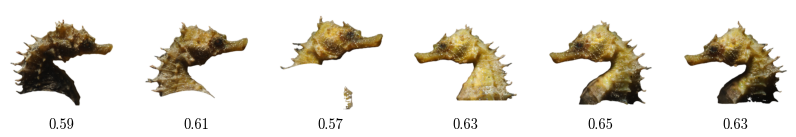

In [11]:
calibration_weights, example_relevance = fit_relevance(example_calibration)
calibration_weighted = score_batches(example_calibration, "miewid_finetuned", calibration_weights)
example_thresholds.append(validation_threshold(calibration_weighted, example_calibration))

example_weights = {name: relevance_weights(example_relevance, batch["relevance_features"])
                   for name, batch in EXAMPLE.items()}
example_weighted = score_batches(EXAMPLE, "miewid_finetuned", example_weights)
show_photographs(EXAMPLE["test_known"]["images"]["name"].tolist(),
                 [f"{weight:.2f}" for weight in np.clip(example_weights["test_known"], RELEVANCE_FLOOR, 1.0)])
show(pd.DataFrame(example_rows(METHODS[2], example_weighted, example_thresholds[2])),
     showIndex=False, paging=False)

## Steps 4 and 5: local matching

The global descriptor shortlists the top 10 identities of each query. For each, the 10
query-image/gallery-image pairs with the highest cosine are matched with ALIKED keypoints and
LightGlue. Step 4 scores a pair by its number of LightGlue matches. Step 5 scores it by the matches that agree with one fundamental matrix fitted by RANSAC, after Nepovinnykh et al. (2025). 

In [22]:
PAIR_CACHE = CACHE_DIR / "aliked_lightglue_pair_geometry.csv"

# Keep raw match counts for step 4 and fundamental-matrix inlier counts for step 5.
PAIR_COLUMNS = ["match_count", "f4"]

# The ALIKED/LightGlue pair cache and the state of the matcher, as one dict. Its "cache" maps each
# score column to {pair key: score}. The models load only when a pair is missing from the cache.
if PAIR_CACHE.exists():
    pair_scores = pd.read_csv(PAIR_CACHE, index_col="pair")[PAIR_COLUMNS].astype(float).to_dict()
else:
    pair_scores = {column: {} for column in PAIR_COLUMNS}
MATCHING = {"path": PAIR_CACHE, "image_path": lambda name: SEGMENTED_COMPRESSED / name, "cache": pair_scores,
            "new": 0, "extractor": None, "lightglue": None, "device": None, "features": {}}
print(f"ALIKED/LightGlue pair cache: {len(MATCHING['cache']['match_count']):,} pairs")

ALIKED/LightGlue pair cache: 367,324 pairs


In [ ]:
from sklearn.preprocessing import minmax_scale

import cv2
import torch
from torchvision.transforms.functional import to_tensor

SHORTLIST_IDENTITIES = 10  # K: gallery identities re-ranked per query observation

PAIRS_PER_IDENTITY = 10    # L: image pairs matched per shortlisted identity

POOL_BEST = 5              # a candidate scores the mean of its best five pair scores

TIEBREAK_EPS = 1e-3        # MiewID survives inside the shortlist only to break ties

MAX_KEYPOINTS = 256

MAX_IMAGE_SIDE = 512

SAVE_EVERY = 4000  # new pairs between two writes of the pair cache

PUBLISHED_SCORE = "f4"  # fundamental-matrix inliers at a 4 px threshold

RANSAC_THRESHOLD = 4.0  # pixels on the image resized to a 512 px longer side

MIN_RANSAC_POINTS = 8

RANSAC_ITERATIONS = 2000

RANSAC_CONFIDENCE = 0.999


def row_minmax(values):
    """Scale finite scores with scikit-learn; non-finite entries become zero."""
    values = np.asarray(values, dtype=np.float32)
    finite = np.isfinite(values)
    scaled = np.zeros_like(values)
    if finite.any():
        scaled[finite] = minmax_scale(values[finite])
    return scaled


def pooled_score(pair_scores):
    """A candidate identity's score: the mean of its POOL_BEST highest pair scores."""
    if len(pair_scores) == 0:
        return UNSCORED
    return float(np.sort(np.asarray(pair_scores, dtype=np.float32))[-POOL_BEST:].mean())


def shortlist(base_scores, gallery_identities, image_similarity, query_groups, gallery_groups,
              valid_mask, k=SHORTLIST_IDENTITIES):
    """The k best gallery identities of each query, and one observation of each.

    The scores repeat each identity's score over its observations, so identities are ranked
    first. Otherwise one well-photographed individual could fill the whole shortlist in the rich
    gallery. Inside an identity, the observation with the best image-to-image cosine is kept.
    """
    masked = np.where(valid_mask, base_scores, -np.inf)
    # The best score of each identity for each query, identities sorted by name, and the columns of
    # each identity.
    identity_best = pd.DataFrame(masked.T).groupby(gallery_identities).max().T
    columns_by_identity = pd.Series(np.arange(len(gallery_identities))).groupby(gallery_identities).indices
    candidates = []
    for query in range(len(masked)):
        ranked = identity_best.iloc[query]
        ranked = ranked[np.isfinite(ranked)].sort_values(ascending=False, kind="stable")  # ties: by name
        chosen = []
        for identity in ranked.index[:k]:
            columns = columns_by_identity[identity]
            columns = columns[np.isfinite(masked[query, columns])]
            if columns.size > 1:
                best = [image_similarity[np.ix_(query_groups[query], gallery_groups[c])].max()
                        for c in columns]
                columns = columns[[np.argmax(best)]]  # the first of tied observations
            chosen.extend(columns)
        candidates.append(np.asarray(chosen, dtype=int))
    return candidates


def best_image_pairs(query_rows, gallery_rows, image_similarity, query_names, gallery_names,
                     k=PAIRS_PER_IDENTITY):
    """The k image pairs with the highest MiewID cosine between two sets of images."""
    scores = image_similarity[np.ix_(query_rows, gallery_rows)]
    if scores.size == 0:
        return []
    keep = min(k, scores.size)
    flat = scores.ravel()
    order = np.argpartition(-flat, keep - 1)[:keep]
    order = order[np.argsort(-flat[order])]
    query_at, gallery_at = np.unravel_index(order, scores.shape)
    return [(query_names[query_rows[a]], gallery_names[gallery_rows[b]])
            for a, b in zip(query_at, gallery_at)]


def candidate_pairs(scores, batch, k=SHORTLIST_IDENTITIES):
    """The shortlisted gallery observations of each query, and the image pairs to match.

    Only the global descriptor chooses them, so steps 4 and 5 match the same pairs. The pairs of
    a candidate come from every eligible observation of its identity, not only the shortlisted
    one, so they are that identity's strongest.
    """
    gallery = batch["gallery"]
    image_similarity = batch["similarity"]["miewid_finetuned"]
    candidates = shortlist(scores, gallery["observation_identities"], image_similarity,
                           batch["image_groups"], gallery["image_groups"],
                           batch["observation_mask"], k)
    query_names = batch["images"]["name"].to_numpy()
    gallery_names = gallery["images"]["name"].to_numpy()
    pairs = []
    for row, columns in enumerate(candidates):
        row_pairs = []
        for column in columns:
            same_identity = np.flatnonzero(
                (gallery["observation_identities"] == gallery["observation_identities"][column])
                & batch["observation_mask"][row])
            gallery_rows = np.concatenate([gallery["image_groups"][c] for c in same_identity])
            row_pairs.append(best_image_pairs(batch["image_groups"][row], gallery_rows,
                                              image_similarity, query_names, gallery_names))
        pairs.append(row_pairs)
    return candidates, pairs


def pair_key(first, second):
    """The cache key of an image pair, the same whichever image is the query."""
    low, high = sorted([first, second])
    return f"{low}::{high}"


def rerank(base_scores, candidates, pairs, valid_mask, pair_scores):
    """Re-order each query's shortlist by its pooled pair score.

    Returns (reranked, pooled). In `reranked`, a shortlisted candidate scores its pooled pair score
    plus a tiny MiewID tie-break, and every other gallery entry sits below, ordered by MiewID
    alone. `pooled` keeps the pure pooled pair scores (NaN off the shortlist) for the step-7 pair
    model, which must not see the tie-break.
    """
    n_queries, n_gallery = base_scores.shape
    reranked = np.empty((n_queries, n_gallery), dtype=np.float32)
    pooled = np.full((n_queries, n_gallery), np.nan, dtype=np.float32)
    for query in range(n_queries):
        reranked[query] = UNSCORED + TIEBREAK_EPS * row_minmax(base_scores[query])
        reranked[query, ~valid_mask[query]] = -np.inf
    for query, columns in enumerate(candidates):
        scores = np.asarray([pooled_score([pair_scores[pair_key(*pair)] for pair in identity_pairs])
                             for identity_pairs in pairs[query]], dtype=np.float32)
        pooled[query, columns] = np.where(scores >= 0, scores, np.nan)
        reranked[query, columns] = scores + TIEBREAK_EPS * row_minmax(base_scores[query, columns])
    return reranked, pooled


def rerank_batches(step, batches, matching, pair_column, k=SHORTLIST_IDENTITIES):
    """Steps 4 and 5 on every batch, from one shortlist and one set of matched pairs.

    Step 4 scores a pair by its LightGlue match count, step 5 by `pair_column`. Pairs missing from
    the cache are matched first. Returns (step 4, step 5, the pooled step-5 pair scores).
    """
    counted, verified, pooled = {}, {}, {}
    for name, batch in batches.items():
        candidates, pairs = candidate_pairs(step[name], batch, k)
        match_missing_pairs(matching, pairs)
        counted[name], _ = rerank(step[name], candidates, pairs, batch["observation_mask"],
                                  matching["cache"]["match_count"])
        verified[name], pooled[name] = rerank(step[name], candidates, pairs,
                                              batch["observation_mask"],
                                              matching["cache"][pair_column])
    return counted, verified, pooled


def load_aliked_lightglue(matching):
    """Load ALIKED and LightGlue"""
    if matching["extractor"] is None:
        from lightglue import ALIKED, LightGlue
        assert torch.cuda.is_available(), "Matching the pairs missing from the pair cache needs a GPU."
        matching["device"] = "cuda"
        matching["extractor"] = ALIKED(max_num_keypoints=MAX_KEYPOINTS).eval().to(matching["device"])
        matching["lightglue"] = LightGlue(features="aliked").eval().to(matching["device"])


@torch.no_grad()
def extract_features(matching, names):
    """ALIKED keypoints of each image, on the image resized to a MAX_IMAGE_SIDE longer side."""
    load_aliked_lightglue(matching)
    for name in names:
        if name in matching["features"]:
            continue
        image = Image.open(matching["image_path"](name)).convert("RGB")
        width, height = image.size
        if max(width, height) > MAX_IMAGE_SIDE:
            scale = MAX_IMAGE_SIDE / max(width, height)
            image = image.resize((max(1, round(width * scale)), max(1, round(height * scale))))
        tensor = to_tensor(image).to(matching["device"])
        matching["features"][name] = {key: value.detach().cpu() if torch.is_tensor(value) else value
                                      for key, value in matching["extractor"].extract(tensor).items()}


@torch.no_grad()
def lightglue_matches(matching, first, second):
    """The pixel positions of the LightGlue matches between two images, one row per match."""
    device = matching["device"]
    result = matching["lightglue"]({
        "image0": {key: value.to(device) for key, value in matching["features"][first].items()},
        "image1": {key: value.to(device) for key, value in matching["features"][second].items()}})
    matches = result["matches"][0].cpu().numpy()
    points0 = matching["features"][first]["keypoints"][0].numpy()[matches[:, 0]]
    points1 = matching["features"][second]["keypoints"][0].numpy()[matches[:, 1]]
    return points0, points1


def save_pair_cache(matching):
    """Write the pair cache to CSV, through a temporary file."""
    table = pd.DataFrame(matching["cache"]).rename_axis("pair").reset_index()
    temporary = matching["path"].with_name(matching["path"].name + ".tmp")
    table.to_csv(temporary, index=False)
    temporary.replace(matching["path"])


def inlier_counts(points0, points1):
    """How many matched keypoints agree with the fundamental matrix fitted by RANSAC."""
    points0 = np.asarray(points0, dtype=np.float64).reshape(-1, 2)
    points1 = np.asarray(points1, dtype=np.float64).reshape(-1, 2)
    if len(points0) < MIN_RANSAC_POINTS:
        return {"f4": 0.0}
    cv2.setRNGSeed(SEED)
    _, mask = cv2.findFundamentalMat(points0, points1, cv2.FM_RANSAC, RANSAC_THRESHOLD,
                                     RANSAC_CONFIDENCE, RANSAC_ITERATIONS)
    return {"f4": 0.0 if mask is None else float(np.asarray(mask).sum())}


def match_missing_pairs(matching, pairs):
    """Match every image pair of `pairs` that the cache does not hold yet, on the GPU if any.

    The two images go in key order, so a pair's score does not depend on which one is the query.
    """
    flat = [pair for query_pairs in pairs for identity_pairs in query_pairs for pair in identity_pairs]
    missing = list(dict.fromkeys(pair_key(*pair) for pair in flat
                                 if pair_key(*pair) not in matching["cache"]["match_count"]))
    if not missing:
        return
    extract_features(matching, sorted({name for key in missing for name in key.split("::")}))
    for key in missing:
        first, second = key.split("::")
        points0, points1 = lightglue_matches(matching, first, second)
        row = {"match_count": float(len(points0)), **inlier_counts(points0, points1)}
        for column in PAIR_COLUMNS:
            matching["cache"][column][key] = row[column]
        matching["new"] += 1
        if matching["new"] % SAVE_EVERY == 0:
            save_pair_cache(matching)
    save_pair_cache(matching)

**Example.** The shortlist of the example in each role: the ten identities with the best
step-3 scores, each with its pooled pair score. Step 4 pools the LightGlue matches, step 5 the
matches that RANSAC keeps.

In [14]:
calibration_counted, calibration_verified, calibration_pooled = rerank_batches(
    calibration_weighted, example_calibration, MATCHING, PUBLISHED_SCORE)
example_thresholds += [validation_threshold(calibration_counted, example_calibration),
                       validation_threshold(calibration_verified, example_calibration)]
example_counted, example_verified, example_pooled = rerank_batches(
    example_weighted, EXAMPLE, MATCHING, PUBLISHED_SCORE)

shortlist_rows = []
for name, role in ROLES.items():
    batch = EXAMPLE[name]
    (columns,), (pairs,) = candidate_pairs(example_weighted[name], batch)
    for column, identity_pairs in zip(columns, pairs):
        keys = [pair_key(*pair) for pair in identity_pairs]
        candidate = batch["gallery"]["observation_identities"][column]
        shortlist_rows.append({
            "Query": role, "Candidate": candidate,
            "Step-3 score": round(float(example_weighted[name][0, column]), 3),
            "Matches (step 4)": round(pooled_score([MATCHING["cache"]["match_count"][key] for key in keys]), 1),
            "RANSAC inliers (step 5)": round(pooled_score([MATCHING["cache"][PUBLISHED_SCORE][key] for key in keys]), 1),
            "True individual": candidate == batch["identities"][0]})
show(pd.DataFrame(shortlist_rows), showIndex=False, paging=False)
show(pd.DataFrame(example_rows(METHODS[3], example_counted, example_thresholds[3])
                  + example_rows(METHODS[4], example_verified, example_thresholds[4])),
     showIndex=False, paging=False)

## Step 6: logistic knownness

In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

KNOWNNESS_C = 0.5


def knownness_features(reranked, weighted, batch):
    """Step 6: five features that say how clearly a query observation matches the gallery.

    - local match margin: the gap between the best and the second-best identity's pooled pair
      score. The best score of a chance match grows with the gallery, the gap does not, so a
      margin transfers from the validation gallery to the larger test gallery.
    - image vote fraction: the share of the observation's photographs whose own top-1 identity
      agrees with the observation's.
    - mean and spread of the image-level MiewID similarity to the winning identity.
    - matchers agree: whether the step-3 scores and the reranked scores pick the same identity.
    """
    gallery_identities = batch["gallery"]["observation_identities"]
    valid_mask = batch["observation_mask"]
    scores, identity_labels = identity_scores(reranked, gallery_identities, valid_mask)
    top = identity_labels[scores.argmax(axis=1)]

    # Pooled pair scores are never negative, so unscored and ineligible entries count as 0.
    ordered = np.sort(np.where(scores > UNSCORED / 2.0, scores, 0.0), axis=1)
    margin = (ordered[:, -1] - ordered[:, -2]) if ordered.shape[1] >= 2 else ordered[:, -1]

    embedding_scores, embedding_labels = identity_scores(weighted, gallery_identities, valid_mask)
    agree = (embedding_labels[embedding_scores.argmax(axis=1)] == top).astype(np.float32)

    n_queries = len(top)
    vote_fraction = np.zeros(n_queries, dtype=np.float32)
    similarity_mean = np.zeros(n_queries, dtype=np.float32)
    similarity_std = np.zeros(n_queries, dtype=np.float32)
    image_scores, image_labels = identity_scores(
        batch["similarity"]["miewid_finetuned"],
        batch["gallery"]["images"]["identity"].to_numpy(str), batch["image_mask"])
    image_top = image_labels[image_scores.argmax(axis=1)]
    image_table = pd.DataFrame(image_scores, columns=image_labels)
    for row, image_rows in enumerate(batch["image_groups"]):
        vote_fraction[row] = np.mean(image_top[image_rows] == top[row])
        values = image_table[top[row]].to_numpy()[image_rows]
        usable = np.isfinite(values)
        if usable.any():
            similarity_mean[row] = values[usable].mean()
            similarity_std[row] = values[usable].std()
    return np.column_stack([margin, vote_fraction, similarity_mean, similarity_std, agree])  # float32


def fit_knownness_model(known_features, unknown_features, known_identities, unknown_identities):
    """A standardised logistic model of P(the query's individual is in the gallery).
    Each individual has the same total weight.
    """
    features = np.vstack([known_features, unknown_features])  # float32
    target = np.r_[np.ones(len(known_features), dtype=int),
                   np.zeros(len(unknown_features), dtype=int)]
    weights = np.r_[compute_sample_weight("balanced", known_identities),
                    compute_sample_weight("balanced", unknown_identities)]
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=4000, C=KNOWNNESS_C, class_weight="balanced",
                                             random_state=SEED))
    model.fit(features, target, standardscaler__sample_weight=weights,
              logisticregression__sample_weight=weights)
    return model


**Example.** The knownness model is fitted on the validation fit part. The five features of the
example and its probability of being known, in each role. Step 6 thresholds that probability.

In [16]:
KNOWNNESS_FEATURES = ["Local match margin", "Image vote fraction", "Similarity mean",
                      "Similarity spread", "Matchers agree"]

calibration_features = {name: knownness_features(calibration_verified[name], calibration_weighted[name], batch)
                        for name, batch in example_calibration.items()}
example_knownness_model = fit_knownness_model(
    calibration_features["fit_known"], calibration_features["fit_unknown"],
    example_calibration["fit_known"]["identities"], example_calibration["fit_unknown"]["identities"])
calibration_knownness = {name: example_knownness_model.predict_proba(features)[:, 1]
                         for name, features in calibration_features.items()}
example_thresholds.append(validation_threshold(calibration_verified, example_calibration,
                                               calibration_knownness))

example_features = {name: knownness_features(example_verified[name], example_weighted[name], batch)
                    for name, batch in EXAMPLE.items()}
example_knownness = {name: example_knownness_model.predict_proba(features)[:, 1]
                     for name, features in example_features.items()}
show(pd.DataFrame([{"Query": role, **{feature: round(float(value), 3) for feature, value in zip(KNOWNNESS_FEATURES, example_features[name][0])},
                    "P(known)": round(float(example_knownness[name][0]), 3)}
                   for name, role in ROLES.items()]), showIndex=False, paging=False)
show(pd.DataFrame(example_rows(METHODS[5], example_verified, example_thresholds[5], example_knownness)),
     showIndex=False, paging=False)

## Step 7: the MAP open-set decision

P(identity | known) comes from Platt-scaling the pooled pair scores into probabilities that two
observations show the same individual, normalised over the shortlist. P(known) is the step-6
model. The decision takes the mode of the posterior over the gallery plus "new".

In [ ]:
from scipy.optimize import minimize_scalar
from scipy.special import logit
from sklearn.metrics import log_loss

TEMPERATURE_LOG_BOUNDS = (-4.0, 4.0)  # T in [0.02, 55]; only a one-class fit reaches an edge

def fit_pair_probability(pooled, batches):
    """Platt-scale the pooled pair scores into P(same individual), on the validation fit part.

    A logistic regression on log(1 + pooled pair score), on the shortlisted entries only and with
    no class weights, so it is calibrated on the candidates it is applied to.
    Returns None when only one class is present.
    """
    gallery_identities = batches["fit_known"]["gallery"]["observation_identities"]
    inputs, labels = [], []
    for name in ("fit_known", "fit_unknown"):
        pooled_name = np.asarray(pooled[name], dtype=np.float64)
        scored = np.isfinite(pooled_name)
        inputs.append(np.log1p(pooled_name[scored])[:, None])
        labels.append((batches[name]["identities"][:, None] == gallery_identities[None, :])[scored]
                      .astype(int))
    x, y = np.concatenate(inputs), np.concatenate(labels)
    if x.shape[0] == 0 or len(np.unique(y)) < 2:
        return None
    logistic = LogisticRegression(max_iter=4000, random_state=SEED)
    return logistic.fit(x, y)


def apply_pair_probability(model, pooled):
    """P(same individual) of each entry; entries off the shortlist get 0."""
    pooled = np.asarray(pooled, dtype=np.float64)
    out = np.zeros(pooled.shape)
    scored = np.isfinite(pooled)
    if model is not None and scored.any():
        out[scored] = model.predict_proba(np.log1p(pooled[scored])[:, None])[:, 1]
    return out


def pooled_pair_auroc(pooled, batches):
    """AUROC of the pooled pair score for 'same individual', on the validation fit part.

    It covers the shortlisted pairs the pair model is fitted on, so it can choose between pair
    scores without the test split.
    """
    gallery_identities = batches["fit_known"]["gallery"]["observation_identities"]
    scores, labels = [], []
    for name in ("fit_known", "fit_unknown"):
        scored = np.isfinite(pooled[name])
        scores.append(pooled[name][scored])
        labels.append((batches[name]["identities"][:, None] == gallery_identities[None, :])[scored])
    return float(roc_auc_score(np.concatenate(labels), np.concatenate(scores)))


def fit_recalibration(probabilities, outcomes):
    """A logistic regression on the logit: it rescales a probability and keeps its ranking."""
    if len(outcomes) == 0 or len(np.unique(outcomes)) < 2:
        return None
    clipped = np.clip(probabilities, 1e-6, 1.0 - 1e-6)
    return LogisticRegression(max_iter=4000, random_state=SEED).fit(logit(clipped)[:, None], outcomes)


def apply_recalibration(model, probabilities):
    """The recalibrated probability; without a model, the probability clipped away from 0 and 1."""
    clipped = np.clip(probabilities, 1e-6, 1.0 - 1e-6)
    if model is None:
        return clipped
    return model.predict_proba(logit(clipped)[:, None])[:, 1]


def apply_temperature(temperature, conditional):
    """s_q proportional to s_q^T on each row. Rows still sum to 1 and no ranking moves."""
    if temperature is None:
        return conditional
    powered = np.where(conditional > 0,
                       np.power(np.clip(conditional, 1e-300, None), temperature), 0.0)
    total = powered.sum(axis=-1, keepdims=True)
    return np.divide(powered, total, out=np.zeros_like(powered), where=total > 0)


def fit_temperature(conditional, correct):
    """The temperature that puts the top-1 share of the identity distribution on its hit rate.

    One temperature acts on every candidate, so the rows stay distributions. Returns None when
    only one class is present: with no miss to learn from, T would run to its bound.
    """
    if len(correct) == 0 or len(np.unique(correct)) < 2:
        return None

    def loss(log_temperature):
        top = np.clip(apply_temperature(np.exp(log_temperature), conditional).max(axis=1),
                      1e-6, 1.0 - 1e-6)
        return log_loss(correct, top)

    return np.exp(minimize_scalar(loss, bounds=TEMPERATURE_LOG_BOUNDS, method="bounded").x)


def conditional_identity_probabilities(probability_matrix, gallery_identities):
    """P(identity | the individual is in the gallery) for each query.

    Each identity takes its best observation's probability, then the row is normalised. A row
    with no scored candidate sums to 0.
    """
    best = pd.DataFrame(probability_matrix.T).groupby(gallery_identities).max()  # identities sorted by name
    identities = best.index.to_numpy(str)
    per_identity = np.ascontiguousarray(best.to_numpy().T)
    total = per_identity.sum(axis=1, keepdims=True)
    return identities, np.divide(per_identity, total, out=np.zeros_like(per_identity),
                                 where=total > 0)


def map_margin(p_known, conditional_identity):
    """The margin of the MAP decision: 0 or more accepts the top identity, below 0 says 'new'.

    P(Y=q | X) = p_known s_q and P(Y=new | X) = 1 - p_known, so the gallery wins exactly when
    p_known (1 + s_top) - 1 > 0. The cut-off moves with s_top: a query with one clear candidate
    is accepted at a lower p_known than one whose candidates tie.
    """
    s_top = conditional_identity.max(axis=1)
    return np.asarray(p_known, dtype=float) * (1.0 + s_top) - 1.0


def fit_map_decision(pooled, knownness, batches):
    """Step 7's calibrated parts, fitted on the validation split.

    P(identity | known) comes from the pair model, normalised over the shortlist. P(known) is the
    step-6 model. Both rank well but sit on the wrong scale, so both are recalibrated on the
    validation scoring part: P(known) by a logistic regression on its logit, the identity
    distribution by one temperature. Neither changes a ranking, and the decision itself has no
    free parameter.
    """
    gallery_identities = batches["score_known"]["gallery"]["observation_identities"]
    pair_probability = fit_pair_probability(pooled, batches)
    identities, conditional = conditional_identity_probabilities(
        apply_pair_probability(pair_probability, pooled["score_known"]),
        gallery_identities)
    correct = (identities[conditional.argmax(axis=1)] == batches["score_known"]["identities"]).astype(int)
    has_evidence = conditional.max(axis=1) > 0
    known_calibration = fit_recalibration(
        np.r_[knownness["score_known"], knownness["score_unknown"]],
        np.r_[np.ones(len(knownness["score_known"]), int),
              np.zeros(len(knownness["score_unknown"]), int)])
    temperature = fit_temperature(conditional[has_evidence], correct[has_evidence])
    return pair_probability, known_calibration, temperature


def apply_map_decision(fitted, pooled, knownness, batches):
    """Step 7: the mode of the posterior over the gallery identities plus 'new'."""
    gallery_identities = batches["test_known"]["gallery"]["observation_identities"]
    conditionals, margins, everywhere = {}, {}, {}
    for name in ("test_known", "test_unknown"):
        identities, conditional = conditional_identity_probabilities(
            apply_pair_probability(fitted["pair_probability"], pooled[name]),
            gallery_identities)
        conditionals[name] = conditional
        margins[name] = map_margin(apply_recalibration(fitted["known_calibration"], knownness[name]),
                                   apply_temperature(fitted["temperature"], conditional))
        # The identity axis is now the shortlist's identities, all live for every query: the
        # gallery-policy mask has done its work upstream.
        everywhere[name] = {**batches[name], "observation_mask": np.ones_like(conditional, dtype=bool)}
    return evaluate(conditionals, everywhere, 0.0, knownness=margins, gallery_identities=identities)

**Example.** The pair model and the two recalibrations are fitted on the validation split. For
each role: P(known) after recalibration, P(new) = 1 - P(known), the three identities with the
highest posterior P(known) s_q, and the MAP margin. A margin of 0 or more accepts the top
identity.

In [18]:
example_pair_probability, example_known_calibration, example_temperature = fit_map_decision(
    calibration_pooled, calibration_knownness, example_calibration)

table_rows = []
for name, role in ROLES.items():
    batch = EXAMPLE[name]
    identities, conditional = conditional_identity_probabilities(
        apply_pair_probability(example_pair_probability, example_pooled[name]),
        batch["gallery"]["observation_identities"])
    conditional = apply_temperature(example_temperature, conditional)[0]
    p_known = float(apply_recalibration(example_known_calibration, example_knownness[name])[0])
    margin = float(map_margin([p_known], conditional[None, :])[0])
    decision = identities[conditional.argmax()] if margin >= 0 else NEW_INDIVIDUAL
    truth = batch["identities"][0]
    table_rows.append({
        "Step": METHODS[6], "Query": role, "P(known)": round(p_known, 3), "P(new)": round(1 - p_known, 3),
        "Best three posteriors": ", ".join(f"{identities[i]} ({p_known * conditional[i]:.3f})"
                                           for i in np.argsort(-conditional)[:3] if conditional[i] > 0),
        "MAP margin": round(margin, 3), "Decision": decision,
        "Right": decision == (truth if name == "test_known" else NEW_INDIVIDUAL)})
show(pd.DataFrame(table_rows), showIndex=False, paging=False)

## The progression

`fit_progression` runs every step on the validation batches and keeps what each step learns.
`apply_progression` scores the test batches with those parts unchanged. 

In [26]:
import gc

def fit_progression(batches, matching, policy, draw, step3=None, pair_column=PUBLISHED_SCORE):
    """Run every step on the validation batches and keep what each step learns.

    `step3`, when given, replaces relevance weighting: it maps the batches to their step-3 score
    matrices. `pair_column` is the pair score of step 5.
    """
    batches = {name: batches[name] for name in CALIBRATION_BATCHES}
    # Steps 1 and 2 fit nothing on the validation queries, so their thresholds use all of them.
    thresholds = [whole_validation_threshold(score_batches(batches, "miewid"), batches),
                  whole_validation_threshold(score_batches(batches, "miewid_finetuned"), batches)]

    relevance = None
    if step3 is None:
        weights, relevance = fit_relevance(batches)
        weighted = score_batches(batches, "miewid_finetuned", weights)
    else:
        weighted = step3(batches)
    thresholds.append(validation_threshold(weighted, batches))

    counted, verified, pooled = rerank_batches(weighted, batches, matching, pair_column)
    thresholds.append(validation_threshold(counted, batches))
    pair_auroc = pooled_pair_auroc(pooled, batches)
    thresholds.append(validation_threshold(verified, batches))

    features = {name: knownness_features(verified[name], weighted[name], batch)
                for name, batch in batches.items()}
    knownness_model = fit_knownness_model(features["fit_known"], features["fit_unknown"],
                                          batches["fit_known"]["identities"],
                                          batches["fit_unknown"]["identities"])
    knownness = {name: knownness_model.predict_proba(features[name])[:, 1]
                 for name in batches}
    thresholds.append(validation_threshold(verified, batches, knownness))

    pair_probability, known_calibration, temperature = fit_map_decision(pooled, knownness, batches)
    gc.collect()  # free the data copies that the fits keep in reference cycles
    return {"policy": policy, "draw": draw, "thresholds": thresholds,
            "relevance_model": relevance, "knownness_model": knownness_model,
            "pair_probability": pair_probability, "known_calibration": known_calibration,
            "temperature": temperature, "step3": step3,
            "pair_column": pair_column, "pair_auroc": pair_auroc}


def apply_progression(fitted, batches, matching, shortlist_k=SHORTLIST_IDENTITIES):
    """Score the test batches with the fitted parts unchanged: one row per step.

    `shortlist_k` changes only how many identities steps 4 and 5 re-rank.
    """
    batches = {name: batches[name] for name in TEST_BATCHES}
    thresholds = fitted["thresholds"]
    rows = [evaluate(score_batches(batches, "miewid"), batches, thresholds[0]),
            evaluate(score_batches(batches, "miewid_finetuned"), batches, thresholds[1])]

    if fitted["step3"] is None:
        weights = {name: relevance_weights(fitted["relevance_model"], batch["relevance_features"])
                   for name, batch in batches.items()}
        weighted = score_batches(batches, "miewid_finetuned", weights)
    else:
        weighted = fitted["step3"](batches)
    rows.append(evaluate(weighted, batches, thresholds[2]))

    counted, verified, pooled = rerank_batches(weighted, batches, matching, fitted["pair_column"],
                                               shortlist_k)
    rows.append(evaluate(counted, batches, thresholds[3]))
    rows.append(evaluate(verified, batches, thresholds[4]))

    features = {name: knownness_features(verified[name], weighted[name], batch)
                for name, batch in batches.items()}
    knownness = {name: fitted["knownness_model"].predict_proba(features[name])[:, 1]
                 for name in batches}
    rows.append(evaluate(verified, batches, thresholds[5], knownness))
    rows.append(apply_map_decision(fitted, pooled, knownness, batches))
    for row in rows:
        row.update(draw=fitted["draw"], policy=fitted["policy"])
    return rows


def run_progression(batches, policy, draw, **options):
    """Fit on the validation batches, then score the test batches: one row per step."""
    fitted = fit_progression(batches, MATCHING, policy, draw, **options)
    return fitted, apply_progression(fitted, batches, MATCHING)


results = {policy: {method: [] for method in METHODS} for policy in GALLERY_POLICIES}

fitted_published = {}

for policy, draw in REPLICATES:
    fitted_published[policy, draw], rows = run_progression(BATCHES[policy, draw], policy, draw)
    for method, row in zip(METHODS, rows):
        results[policy][method].append(row)

for policy in GALLERY_POLICIES:
    print(f"{GALLERY_POLICIES[policy]}: {len(results[policy][METHODS[0]])} replicates")

print(f"{MATCHING['new']:,} pairs matched in this run")


Sparse gallery (one observation per individual): 5 replicates
Rich gallery (all observations except the query): 1 replicates
0 pairs matched in this run


## Uncertainty

Each bootstrap sample draws one multiset of test individuals.

In [28]:
from scipy.stats import bootstrap

ALPHA = 0.05  # 95% intervals
N_BOOT = 1000

REID_METRIC_NAMES = ("BAKS", "BAUS", "BRA", "normalized_accuracy", "knownness_AUROC",
                     "closed_top1", "closed_balanced_accuracy")

REID_METRICS = [("BAKS", "BAKS ↑"), ("BAUS", "BAUS ↑"), ("BRA", "BRA ↑"),
                ("normalized_accuracy", "NA ↑")]


def per_identity_counts(row, index):
    """One result row reduced to sums per individual, so a bootstrap draw is a dot product.

    The rank of each known score among the unknown scores turns AUROC into a dot product too.
    """
    threshold = row["threshold"]
    known_identities, known_scores = row["known_identities"], row["known_scores"]
    unknown_identities, unknown_scores = row["unknown_identities"], row["unknown_scores"]
    correct = row["known_predictions"] == known_identities
    accepted_and_correct = correct & (known_scores >= threshold)
    rejected = unknown_scores < threshold

    n = len(index)
    known_row = index[known_identities].to_numpy()
    unknown_row = index[unknown_identities].to_numpy()
    known_n = np.bincount(known_row, minlength=n)
    unknown_n = np.bincount(unknown_row, minlength=n)
    order = np.argsort(unknown_scores, kind="mergesort")
    sorted_unknown = unknown_scores[order]
    return {"known_n": known_n, "has_known": known_n > 0, "has_unknown": unknown_n > 0,
            # Per individual, the share of its queries that are accepted and right, right, or rejected.
            "baks_per_identity": (np.bincount(known_row, weights=accepted_and_correct, minlength=n)
                                  / np.maximum(known_n, 1.0)),
            "closed_per_identity": (np.bincount(known_row, weights=correct, minlength=n)
                                    / np.maximum(known_n, 1.0)),
            "baus_per_identity": (np.bincount(unknown_row, weights=rejected, minlength=n)
                                  / np.maximum(unknown_n, 1.0)),
            "correct_total": np.bincount(known_row, weights=correct, minlength=n),
            "known_row": known_row, "unknown_row_sorted": unknown_row[order],
            # Ties split evenly, as in roc_auc_score.
            "rank_low": np.searchsorted(sorted_unknown, known_scores, side="left"),
            "rank_high": np.searchsorted(sorted_unknown, known_scores, side="right")}


def weighted_metrics(counts, multiplicity):
    """One row's metrics when individual i is drawn multiplicity[i] times.

    BAKS, BAUS and closed-set balanced accuracy average over individuals, so they must carry the
    multiplicities. Duplicating rows and calling a macro recall would drop them.
    """
    known_weight = multiplicity * counts["has_known"]
    unknown_weight = multiplicity * counts["has_unknown"]
    n_known, n_unknown = known_weight.sum(), unknown_weight.sum()
    if n_known <= 0 or n_unknown <= 0:
        return {name: float("nan") for name in REID_METRIC_NAMES}
    baks_value = known_weight @ counts["baks_per_identity"] / n_known
    baus_value = unknown_weight @ counts["baus_per_identity"] / n_unknown
    known_rows = multiplicity[counts["known_row"]]
    unknown_rows = multiplicity[counts["unknown_row_sorted"]]
    cumulative = np.concatenate(([0.0], np.cumsum(unknown_rows)))
    below = cumulative[counts["rank_low"]]
    tied = cumulative[counts["rank_high"]] - below
    alpha = n_known / (n_known + n_unknown)
    return {"BAKS": baks_value, "BAUS": baus_value,
            "BRA": alpha * baks_value + (1.0 - alpha) * baus_value,  # alpha-weighted mean
            "normalized_accuracy": np.sqrt(max(baks_value, 0.0) * max(baus_value, 0.0)),
            "knownness_AUROC": known_rows @ (below + 0.5 * tied) / (known_rows.sum() * cumulative[-1]),
            "closed_top1": multiplicity @ counts["correct_total"] / (multiplicity @ counts["known_n"]),
            "closed_balanced_accuracy": known_weight @ counts["closed_per_identity"] / n_known}


def mean_over_draws(cells, multiplicity):
    """The metrics averaged over the gallery draws of one method."""
    per_draw = [weighted_metrics(cell, multiplicity) for cell in cells]
    averaged = {}
    for name in REID_METRIC_NAMES:
        values = np.asarray([row[name] for row in per_draw], dtype=float)
        finite = values[np.isfinite(values)]
        averaged[name] = finite.mean() if finite.size else float("nan")
    return averaged


def identity_bootstrap(methods, statistic):
    """{metric: (point, low, high)} of a statistic of several methods, resampling the test individuals.

    `methods` holds, for each method, its result rows (one per gallery draw). `statistic` maps the
    metrics {name: value} of every method to one value per name of REID_METRIC_NAMES. scipy
    resamples the individual numbers. Each draw is one multiset of test individuals, applied to
    every gallery draw, both query roles and every method, so a statistic can subtract two methods
    draw by draw. The thresholds and the gallery stay fixed.
    """
    identities = query_identities([row for rows in methods for row in rows])
    index = pd.Series(np.arange(len(identities)), index=identities)  # identity -> position
    cells = [[per_identity_counts(row, index) for row in rows] for rows in methods]

    def resampled(drawn):
        multiplicity = np.bincount(drawn.astype(int), minlength=len(identities)).astype(float)
        metrics = statistic([mean_over_draws(method, multiplicity) for method in cells])
        return np.array([metrics[name] for name in REID_METRIC_NAMES])

    everyone = np.arange(len(identities))
    result = bootstrap((everyone,), resampled, vectorized=False, n_resamples=N_BOOT,
                       confidence_level=1 - ALPHA, method="percentile",
                       rng=np.random.default_rng(SEED))
    return dict(zip(REID_METRIC_NAMES, zip(resampled(everyone), *result.confidence_interval)))


def identity_bootstrap_ci(rows):
    """{metric: (point, low, high)} of one method, resampling the test individuals."""
    return identity_bootstrap([rows], lambda metrics: metrics[0])


for policy, methods in results.items():
    print(f"{GALLERY_POLICIES[policy]}: "
          f"{len(query_identities(results[policy][METHODS[0]]))} test individuals")


Sparse gallery (one observation per individual): 95 test individuals


Rich gallery (all observations except the query): 95 test individuals


### Table 6 — Progression with a sparse gallery 

In [29]:
from IPython.display import Markdown, display

PRECISION = 2  # decimals of every number in every table
ARROWS = str.maketrans({"↑": r"$\uparrow$", "↓": r"$\downarrow$"})


def format_ci(cell, latex=False):
    """A (point, low, high) cell as 'point [low, high]', or '-' without a point.

    A fourth value, the change from the row above, follows in parentheses: '(+0.05)', or '(-)'
    when it is None.
    """
    point, low, high, *change = cell
    if not np.isfinite(point):
        return r"\textemdash{}" if latex else "-"
    text = f"{point:.{PRECISION}f}"
    if np.isfinite(low) and np.isfinite(high):
        text += f" [{low:.{PRECISION}f}, {high:.{PRECISION}f}]"
    if change:
        text += " (-)" if change[0] is None else f" ({change[0]:+.{PRECISION}f})"
    return text


def show_table(frame, caption, label, bold_best=True):
    """Display the table, sortable and searchable, then its booktabs LaTeX.

    The caption is LaTeX. The columns of (point, low, high) cells are right-aligned. With
    bold_best, bold marks the best printed point of each column whose header ends in ↑ or ↓.
    """
    intervals = [column for column in frame if isinstance(frame[column].iloc[0], tuple)]
    styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for column in intervals:
        if bold_best and column.endswith(("↑", "↓")):
            printed = frame[column].map(lambda cell: round(cell[0], PRECISION))
            best = printed.max() if column.endswith("↑") else printed.min()
            styles[column] = np.where(printed == best, "textbf:--rwrap;", "")
    latex = (frame.style.hide(axis="index")
             .format(lambda cell: format_ci(cell, latex=True), subset=intervals)
             .apply(lambda _: styles, axis=None)
             .format_index(lambda header: header.translate(ARROWS), axis=1)
             .to_latex(hrules=True, caption=caption, label=label, position="htbp",
                       position_float="centering",
                       column_format="".join("r" if column in intervals else "l"
                                             for column in frame)))
    show(frame.assign(**{column: frame[column].map(format_ci) for column in intervals}),
         showIndex=False, paging=False)
    display(Markdown(f"**`{label}`**\n\n```latex\n{latex}\n```"))


def reid_table(rows_by_method):
    """One row per method, each cell a (point, low, high, change from the row above) tuple.

    The point is the mean over gallery draws. The interval resamples the test individuals.
    """
    rows, previous = [], None
    for method, method_rows in rows_by_method.items():
        interval = identity_bootstrap_ci(method_rows)
        row = {"Method": method}
        for key, header in REID_METRICS:
            point, low, high = interval[key]
            row[header] = (point, low, high, None if previous is None else point - previous[key][0])
        rows.append(row)
        previous = interval
    return pd.DataFrame(rows)


show_table(reid_table(results[SPARSE_GALLERY]),
           label="tab:reid_progression_one_observation_per_individual",
           caption='Seahorse re-ID with a sparse gallery. Cells are means over five gallery draws within the test split, with 95\\% bootstrap intervals over test individuals in brackets and the change from the row above in parentheses.')

Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
1. MiewID zero-shot,"0.24 [0.19, 0.31] (-)","0.54 [0.47, 0.60] (-)","0.43 [0.38, 0.48] (-)","0.36 [0.31, 0.41] (-)"
2. + MiewID fine-tuning,"0.57 [0.50, 0.64] (+0.33)","0.74 [0.68, 0.80] (+0.21)","0.68 [0.63, 0.73] (+0.25)","0.65 [0.60, 0.70] (+0.29)"
3. + relevance weighting,"0.64 [0.56, 0.71] (+0.07)","0.55 [0.48, 0.62] (-0.20)","0.58 [0.53, 0.64] (-0.10)","0.59 [0.53, 0.64] (-0.06)"
4. + ALIKED/LightGlue rerank,"0.70 [0.63, 0.78] (+0.07)","0.67 [0.60, 0.73] (+0.12)","0.68 [0.63, 0.73] (+0.10)","0.69 [0.64, 0.73] (+0.09)"
5. + RANSAC verification,"0.70 [0.62, 0.78] (-0.00)","0.91 [0.86, 0.95] (+0.24)","0.83 [0.79, 0.87] (+0.15)","0.80 [0.75, 0.84] (+0.11)"
6. + logistic knownness,"0.76 [0.69, 0.82] (+0.06)","0.88 [0.84, 0.92] (-0.02)","0.84 [0.80, 0.87] (+0.01)","0.82 [0.77, 0.86] (+0.02)"
7. + MAP open-set decision,"0.77 [0.70, 0.83] (+0.02)","0.88 [0.84, 0.92] (+0.00)","0.84 [0.80, 0.88] (+0.01)","0.83 [0.78, 0.86] (+0.01)"


**`tab:reid_progression_one_observation_per_individual`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{lrrrr}
\toprule
Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
1. MiewID zero-shot & 0.24 [0.19, 0.31] (-) & 0.54 [0.47, 0.60] (-) & 0.43 [0.38, 0.48] (-) & 0.36 [0.31, 0.41] (-) \\
2. + MiewID fine-tuning & 0.57 [0.50, 0.64] (+0.33) & 0.74 [0.68, 0.80] (+0.21) & 0.68 [0.63, 0.73] (+0.25) & 0.65 [0.60, 0.70] (+0.29) \\
3. + relevance weighting & 0.64 [0.56, 0.71] (+0.07) & 0.55 [0.48, 0.62] (-0.20) & 0.58 [0.53, 0.64] (-0.10) & 0.59 [0.53, 0.64] (-0.06) \\
4. + ALIKED/LightGlue rerank & 0.70 [0.63, 0.78] (+0.07) & 0.67 [0.60, 0.73] (+0.12) & 0.68 [0.63, 0.73] (+0.10) & 0.69 [0.64, 0.73] (+0.09) \\
5. + RANSAC verification & 0.70 [0.62, 0.78] (-0.00) & \textbf{0.91 [0.86, 0.95] (+0.24)} & 0.83 [0.79, 0.87] (+0.15) & 0.80 [0.75, 0.84] (+0.11) \\
6. + logistic knownness & 0.76 [0.69, 0.82] (+0.06) & 0.88 [0.84, 0.92] (-0.02) & \textbf{0.84 [0.80, 0.87] (+0.01)} & 0.82 [0.77, 0.86] (+0.02) \\
7. + MAP open-set decision & \textbf{0.77 [0.70, 0.83] (+0.02)} & 0.88 [0.84, 0.92] (+0.00) & \textbf{0.84 [0.80, 0.88] (+0.01)} & \textbf{0.83 [0.78, 0.86] (+0.01)} \\
\bottomrule
\end{tabular}
\caption{Seahorse re-ID with a sparse gallery. Cells are means over five gallery draws within the test split, with 95\% bootstrap intervals over test individuals in brackets and the change from the row above in parentheses.}
\label{tab:reid_progression_one_observation_per_individual}
\end{table}

```

### Table 7 — Progression with a rich gallery

In [30]:
show_table(reid_table(results[RICH_GALLERY]),
           label="tab:reid_progression_all_except_query",
           caption='Seahorse re-ID with a rich gallery. Cells are computed on the test split, with 95\\% bootstrap intervals over test individuals in brackets and the change from the row above in parentheses.')

Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
1. MiewID zero-shot,"0.44 [0.35, 0.54] (-)","0.45 [0.37, 0.53] (-)","0.45 [0.38, 0.51] (-)","0.45 [0.38, 0.51] (-)"
2. + MiewID fine-tuning,"0.73 [0.63, 0.82] (+0.29)","0.68 [0.61, 0.75] (+0.23)","0.70 [0.65, 0.75] (+0.25)","0.70 [0.65, 0.76] (+0.26)"
3. + relevance weighting,"0.70 [0.61, 0.79] (-0.03)","0.92 [0.87, 0.96] (+0.24)","0.84 [0.79, 0.88] (+0.14)","0.80 [0.74, 0.86] (+0.10)"
4. + ALIKED/LightGlue rerank,"0.79 [0.69, 0.87] (+0.08)","0.87 [0.80, 0.92] (-0.06)","0.84 [0.79, 0.88] (-0.00)","0.83 [0.77, 0.87] (+0.02)"
5. + RANSAC verification,"0.86 [0.78, 0.93] (+0.08)","0.87 [0.81, 0.92] (+0.00)","0.87 [0.82, 0.91] (+0.03)","0.87 [0.82, 0.91] (+0.04)"
6. + logistic knownness,"0.86 [0.77, 0.93] (+0.00)","0.92 [0.88, 0.96] (+0.05)","0.90 [0.85, 0.94] (+0.03)","0.89 [0.84, 0.93] (+0.03)"
7. + MAP open-set decision,"0.86 [0.76, 0.93] (-0.01)","0.94 [0.90, 0.98] (+0.02)","0.91 [0.87, 0.95] (+0.01)","0.90 [0.85, 0.94] (+0.01)"


**`tab:reid_progression_all_except_query`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{lrrrr}
\toprule
Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
1. MiewID zero-shot & 0.44 [0.35, 0.54] (-) & 0.45 [0.37, 0.53] (-) & 0.45 [0.38, 0.51] (-) & 0.45 [0.38, 0.51] (-) \\
2. + MiewID fine-tuning & 0.73 [0.63, 0.82] (+0.29) & 0.68 [0.61, 0.75] (+0.23) & 0.70 [0.65, 0.75] (+0.25) & 0.70 [0.65, 0.76] (+0.26) \\
3. + relevance weighting & 0.70 [0.61, 0.79] (-0.03) & 0.92 [0.87, 0.96] (+0.24) & 0.84 [0.79, 0.88] (+0.14) & 0.80 [0.74, 0.86] (+0.10) \\
4. + ALIKED/LightGlue rerank & 0.79 [0.69, 0.87] (+0.08) & 0.87 [0.80, 0.92] (-0.06) & 0.84 [0.79, 0.88] (-0.00) & 0.83 [0.77, 0.87] (+0.02) \\
5. + RANSAC verification & \textbf{0.86 [0.78, 0.93] (+0.08)} & 0.87 [0.81, 0.92] (+0.00) & 0.87 [0.82, 0.91] (+0.03) & 0.87 [0.82, 0.91] (+0.04) \\
6. + logistic knownness & \textbf{0.86 [0.77, 0.93] (+0.00)} & 0.92 [0.88, 0.96] (+0.05) & 0.90 [0.85, 0.94] (+0.03) & 0.89 [0.84, 0.93] (+0.03) \\
7. + MAP open-set decision & \textbf{0.86 [0.76, 0.93] (-0.01)} & \textbf{0.94 [0.90, 0.98] (+0.02)} & \textbf{0.91 [0.87, 0.95] (+0.01)} & \textbf{0.90 [0.85, 0.94] (+0.01)} \\
\bottomrule
\end{tabular}
\caption{Seahorse re-ID with a rich gallery. Cells are computed on the test split, with 95\% bootstrap intervals over test individuals in brackets and the change from the row above in parentheses.}
\label{tab:reid_progression_all_except_query}
\end{table}

```

## Benchmark: Quality Aware Network

Step 3 learns a weight per photograph from a label: did the fine-tuned model identify the animal
from this photograph alone? 
In QAN (Liu, Yan and Ouyang, CVPR 2017), each image gets a quality between 0 and 1, the set feature is the
quality-weighted mean of the image features, and a triplet loss on the set features is used to train the
quality unit.

We keep QAN's quality unit, its set pooling and its set-level triplet loss, but the fine-tuned MiewID stays frozen, 
and the quality unit, one linear layer and a sigmoid, reads its embeddings.  

Every query observation and every gallery observation becomes one set feature. 
We compare:

- step 2: the plain mean of the image scores
- QAN pooling with every photograph equal: the move from pooling scores to pooling features
- QAN pooling with the learned quality: the QAN benchmark
- step 3: our relevance weighting

A caveat: MiewID was fine-tuned on the training split, so its training embeddings already separate the individuals well. The set loss may then give the quality unit little to learn. 

In [32]:
import torch.nn as nn

QAN_IDENTITIES = 16   # individuals per training batch
QAN_OBSERVATIONS = 4  # observations per individual, at most
QAN_SET_SIZE = 8      # photographs per training set, at most; the size is drawn from 1 up
QAN_MARGIN = 0.3      # triplet margin, in cosine distance
QAN_STEPS = 2000
QAN_LEARNING_RATE = 1e-3
QAN_WEIGHT_DECAY = 1e-4


def training_index(identities, observations):
    """The rows of each observation, the observations of each individual, and the individuals
    with two or more observations (only those give a positive pair of sets)."""
    frame = pd.DataFrame({"identity": identities, "observation": observations}).astype(str)
    rows_by_observation = frame.groupby("observation", sort=False).indices
    observations_by_identity = (frame.drop_duplicates("observation")
                                .groupby("identity", sort=False)["observation"].agg(list).to_dict())
    counts = frame.groupby("identity")["observation"].nunique()
    return rows_by_observation, observations_by_identity, counts.index[counts >= 2].tolist()


@torch.no_grad()
def qan_quality(unit, embeddings):
    """The quality of each row of an embedding matrix."""
    unit.eval()
    return unit(torch.as_tensor(np.asarray(embeddings, dtype=np.float32))).squeeze(-1).numpy()


train_embeddings = take(EMB["miewid_finetuned"], train["name"].tolist())
# Train the quality unit with a batch-hard triplet loss on set features.
# Each step draws QAN_IDENTITIES individuals, up to QAN_OBSERVATIONS observations of each, and a
# random subset of each observation's photographs, as QAN's random sub-sequences. The unit sees one
# observation under many compositions and cannot learn the set size. The weights start at zero, so
# training starts from plain mean pooling.
embeddings = np.asarray(train_embeddings, dtype=np.float32)
rows_by_observation, observations_by_identity, eligible = training_index(train["identity"], train["observation"])
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
qan_unit = nn.Sequential(nn.Linear(embeddings.shape[1], 1), nn.Sigmoid())
nn.init.zeros_(qan_unit[0].weight)
nn.init.zeros_(qan_unit[0].bias)
optimizer = torch.optim.Adam(qan_unit.parameters(), lr=QAN_LEARNING_RATE, weight_decay=QAN_WEIGHT_DECAY)
features = torch.from_numpy(embeddings)
qan_losses = []
qan_unit.train()
for _ in range(QAN_STEPS):
    rows, set_index, set_labels = [], [], []
    drawn = rng.choice(len(eligible), size=min(QAN_IDENTITIES, len(eligible)), replace=False)
    for label, identity in enumerate(np.asarray(eligible)[drawn]):
        owned = observations_by_identity[identity]
        for observation in rng.choice(owned, size=min(QAN_OBSERVATIONS, len(owned)), replace=False):
            available = rows_by_observation[observation]
            size = int(rng.integers(1, min(QAN_SET_SIZE, len(available)) + 1))
            rows.extend(rng.choice(available, size=size, replace=False).tolist())
            set_index.extend([len(set_labels)] * size)
            set_labels.append(label)
    batch = features[rows]
    # Quality-weighted set means, as qan_scores pools them (QAN's group L1 normalisation).
    quality = qan_unit(batch).squeeze(-1)
    index = torch.as_tensor(set_index)
    weighted = torch.zeros(len(set_labels), batch.shape[1], dtype=batch.dtype).index_add_(
        0, index, quality[:, None] * batch)
    total = torch.zeros(len(set_labels), dtype=quality.dtype).index_add_(0, index, quality)
    pooled = nn.functional.normalize(weighted / total[:, None], dim=1)
    # The batch-hard triplet loss: each set against its farthest positive and its nearest negative, in cosine distance.
    targets = torch.as_tensor(set_labels)
    distance = 1.0 - pooled @ pooled.T
    same = targets[:, None] == targets[None, :]
    other_self = same & ~torch.eye(len(targets), dtype=torch.bool)
    hardest_positive = torch.where(other_self, distance, torch.full_like(distance, -torch.inf)).amax(dim=1)
    hardest_negative = torch.where(~same, distance, torch.full_like(distance, torch.inf)).amin(dim=1)
    loss = torch.relu(hardest_positive - hardest_negative + QAN_MARGIN).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    qan_losses.append(loss.item())
qan_unit.eval()
train_quality = qan_quality(qan_unit, train_embeddings)
print(f"QAN quality unit: {QAN_STEPS} steps on {train['identity'].nunique()} training "
      f"individuals, {len(train):,} photographs")
print(f"  triplet loss, mean of the first and last 100 steps: "
      f"{np.mean(qan_losses[:100]):.4f} -> {np.mean(qan_losses[-100:]):.4f}")
print(f"  quality on the training split: std {train_quality.std():.3f}, "
      f"5th-95th percentile {np.percentile(train_quality, 5):.3f}-{np.percentile(train_quality, 95):.3f}")

QAN quality unit: 2000 steps on 332 training individuals, 21,381 photographs
  triplet loss, mean of the first and last 100 steps: 0.1129 -> 0.1009
  quality on the training split: std 0.075, 5th-95th percentile 0.104-0.335


In [33]:
QAN_UNIFORM, QAN_LEARNED = "QAN pooling, uniform quality", "QAN pooling, learned quality"


def qan_scores(batches, unit=None):
    """Every batch scored by QAN set pooling: the cosine between query and gallery set features.

    Without a unit every photograph counts the same.
    """
    def sets(images, groups):
        """One unit-length feature per group: the quality-weighted mean of its embeddings."""
        embeddings = take(EMB["miewid_finetuned"], images["name"].tolist())
        quality = (np.ones(len(embeddings)) if unit is None
                   else np.asarray(qan_quality(unit, embeddings), dtype=np.float64))
        embeddings = np.asarray(embeddings, dtype=np.float64)
        pooled = np.vstack([np.average(embeddings[rows], axis=0, weights=quality[rows]) for rows in groups])
        return normalize(pooled, norm="l2", axis=1).astype(np.float32)

    gallery_sets = {}
    for batch in batches.values():
        gallery = batch["gallery"]
        if gallery["name"] not in gallery_sets:
            gallery_sets[gallery["name"]] = sets(gallery["images"], gallery["image_groups"])
    return {name: sets(batch["images"], batch["image_groups"]) @ gallery_sets[batch["gallery"]["name"]].T
            for name, batch in batches.items()}


def calibrated_row(step, batches, policy, draw, whole_validation=False):
    """Score a step on the test batches at a threshold chosen on validation."""
    if whole_validation:
        threshold = whole_validation_threshold(step, batches)
    else:
        threshold = validation_threshold(step, batches)
    return {**evaluate(step, batches, threshold), "draw": draw, "policy": policy}


qan_results = {policy: {QAN_UNIFORM: [], QAN_LEARNED: []} for policy in GALLERY_POLICIES}
for policy, draw in REPLICATES:
    batches = BATCHES[policy, draw]
    qan_results[policy][QAN_UNIFORM].append(calibrated_row(qan_scores(batches), batches, policy, draw))
    qan_results[policy][QAN_LEARNED].append(
        calibrated_row(qan_scores(batches, qan_unit), batches, policy, draw))

### QAN benchmark against relevance weighting

In [34]:
def stacked_reid_table(blocks, label_columns=("Gallery",)):
    """One reid_table per block, stacked, so the change column stays inside a block."""
    frames = [reid_table(methods).assign(**dict(zip(label_columns, labels)))
              for labels, methods in blocks.items()]
    stacked = pd.concat(frames, ignore_index=True)
    return stacked[[*label_columns, "Method", *(header for _, header in REID_METRICS)]]

GALLERY_LABELS = [(SPARSE_GALLERY, "Sparse"), (RICH_GALLERY, "Rich")]
# Each change reads as one move: score pooling -> feature pooling -> learned QAN quality ->
# relevance weighting. One reid_table per policy keeps the changes inside a policy.
show_table(stacked_reid_table({
    (label,): {METHODS[1]: results[policy][METHODS[1]],
               QAN_UNIFORM: qan_results[policy][QAN_UNIFORM],
               QAN_LEARNED: qan_results[policy][QAN_LEARNED],
               METHODS[2]: results[policy][METHODS[2]]}
    for policy, label in GALLERY_LABELS}),
    label="tab:reid_qan_benchmark",
    caption='QAN benchmark against relevance weighting, under both gallery policies. All rows use the fine-tuned MiewID embeddings and threshold the best identity score.')

Gallery,Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
Sparse,2. + MiewID fine-tuning,"0.57 [0.50, 0.64] (-)","0.74 [0.68, 0.80] (-)","0.68 [0.63, 0.73] (-)","0.65 [0.60, 0.70] (-)"
Sparse,"QAN pooling, uniform quality","0.54 [0.45, 0.62] (-0.03)","0.79 [0.73, 0.84] (+0.05)","0.70 [0.65, 0.74] (+0.02)","0.65 [0.60, 0.70] (+0.00)"
Sparse,"QAN pooling, learned quality","0.59 [0.50, 0.67] (+0.05)","0.73 [0.66, 0.80] (-0.06)","0.68 [0.63, 0.73] (-0.02)","0.66 [0.60, 0.71] (+0.00)"
Sparse,3. + relevance weighting,"0.64 [0.56, 0.71] (+0.05)","0.55 [0.48, 0.62] (-0.18)","0.58 [0.53, 0.64] (-0.10)","0.59 [0.53, 0.64] (-0.07)"
Rich,2. + MiewID fine-tuning,"0.73 [0.63, 0.82] (-)","0.68 [0.61, 0.75] (-)","0.70 [0.65, 0.75] (-)","0.70 [0.65, 0.76] (-)"
Rich,"QAN pooling, uniform quality","0.82 [0.73, 0.89] (+0.09)","0.71 [0.64, 0.78] (+0.03)","0.75 [0.70, 0.80] (+0.05)","0.76 [0.71, 0.81] (+0.06)"
Rich,"QAN pooling, learned quality","0.84 [0.75, 0.91] (+0.02)","0.62 [0.54, 0.69] (-0.09)","0.70 [0.64, 0.76] (-0.05)","0.72 [0.67, 0.77] (-0.04)"
Rich,3. + relevance weighting,"0.70 [0.61, 0.79] (-0.13)","0.92 [0.87, 0.96] (+0.30)","0.84 [0.79, 0.88] (+0.14)","0.80 [0.74, 0.86] (+0.09)"


**`tab:reid_qan_benchmark`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{llrrrr}
\toprule
Gallery & Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
Sparse & 2. + MiewID fine-tuning & 0.57 [0.50, 0.64] (-) & 0.74 [0.68, 0.80] (-) & 0.68 [0.63, 0.73] (-) & 0.65 [0.60, 0.70] (-) \\
Sparse & QAN pooling, uniform quality & 0.54 [0.45, 0.62] (-0.03) & 0.79 [0.73, 0.84] (+0.05) & 0.70 [0.65, 0.74] (+0.02) & 0.65 [0.60, 0.70] (+0.00) \\
Sparse & QAN pooling, learned quality & 0.59 [0.50, 0.67] (+0.05) & 0.73 [0.66, 0.80] (-0.06) & 0.68 [0.63, 0.73] (-0.02) & 0.66 [0.60, 0.71] (+0.00) \\
Sparse & 3. + relevance weighting & 0.64 [0.56, 0.71] (+0.05) & 0.55 [0.48, 0.62] (-0.18) & 0.58 [0.53, 0.64] (-0.10) & 0.59 [0.53, 0.64] (-0.07) \\
Rich & 2. + MiewID fine-tuning & 0.73 [0.63, 0.82] (-) & 0.68 [0.61, 0.75] (-) & 0.70 [0.65, 0.75] (-) & 0.70 [0.65, 0.76] (-) \\
Rich & QAN pooling, uniform quality & 0.82 [0.73, 0.89] (+0.09) & 0.71 [0.64, 0.78] (+0.03) & 0.75 [0.70, 0.80] (+0.05) & 0.76 [0.71, 0.81] (+0.06) \\
Rich & QAN pooling, learned quality & \textbf{0.84 [0.75, 0.91] (+0.02)} & 0.62 [0.54, 0.69] (-0.09) & 0.70 [0.64, 0.76] (-0.05) & 0.72 [0.67, 0.77] (-0.04) \\
Rich & 3. + relevance weighting & 0.70 [0.61, 0.79] (-0.13) & \textbf{0.92 [0.87, 0.96] (+0.30)} & \textbf{0.84 [0.79, 0.88] (+0.14)} & \textbf{0.80 [0.74, 0.86] (+0.09)} \\
\bottomrule
\end{tabular}
\caption{QAN benchmark against relevance weighting, under both gallery policies. All rows use the fine-tuned MiewID embeddings and threshold the best identity score.}
\label{tab:reid_qan_benchmark}
\end{table}

```

In [35]:
from scipy.stats import spearmanr

# Do QAN and relevance weighting value the same photographs? Both weight the test known
# queries. A rank correlation near zero means they learned different ideas of a good photograph.
relevance_batches = BATCHES[SPARSE_GALLERY, 0]
relevance_test = relevance_batches["test_known"]["images"].assign(
    relevance=fit_relevance(relevance_batches)[0]["test_known"])
qan_test = qan_quality(qan_unit, take(EMB["miewid_finetuned"], relevance_test["name"].tolist()))
rho, _ = spearmanr(qan_test, relevance_test["relevance"])
print(f"{len(relevance_test):,} test photographs: Spearman rho between QAN quality and "
      f"step-3 relevance = {rho:.2f}")
print(f"QAN quality on the test split: std {qan_test.std():.3f}, "
      f"5th-95th percentile {np.percentile(qan_test, 5):.3f}-{np.percentile(qan_test, 95):.3f}")

6,118 test photographs: Spearman rho between QAN quality and step-3 relevance = 0.71
QAN quality on the test split: std 0.072, 5th-95th percentile 0.105-0.327


### QAN followed by steps 4-7

The progression again, with QAN pooling in place of relevance weighting at step 3. Steps 4-7 do
not change and build on whatever step 3 gives. The shortlist of the rerank comes from the step-3
scores, so another step 3 can shortlist other individuals. The "matchers agree" feature of
step 6 also compares with the step-3 top-1 identity. Steps 1 and 2 are those of Tables 6 and 7
and are not repeated. Both quality variants run: the learned quality, the QAN benchmark, and the
uniform quality, which pooled better on its own above.

In [36]:
LATE_STEPS = METHODS[2:]
QAN_UNITS = {QAN_LEARNED: qan_unit, QAN_UNIFORM: None}

late_results = {policy: {"Relevance weighting": {step: results[policy][step] for step in LATE_STEPS},
                         **{variant: {step: [] for step in LATE_STEPS} for variant in QAN_UNITS}}
                for policy in GALLERY_POLICIES}
for policy, draw in REPLICATES:
    for variant, unit in QAN_UNITS.items():
        _, rows = run_progression(BATCHES[policy, draw], policy, draw,
                                  step3=lambda batches, unit=unit: qan_scores(batches, unit))
        for step, row in zip(LATE_STEPS, rows[2:]):
            late_results[policy][variant][step].append(row)


In [37]:
STEP3_ALONE = "3. step 3 alone"

late_table = stacked_reid_table({(label, variant): late_results[policy][variant]
                                 for policy, label in GALLERY_LABELS for variant in late_results[policy]},
                                label_columns=("Gallery", "Step 3"))
late_table["Method"] = late_table["Method"].str.replace(METHODS[2], STEP3_ALONE, regex=False)
show_table(late_table, label="tab:reid_qan_late_steps", bold_best=False,
           caption='Steps 3 to 7 of the re-identification system under three choices of step 3: relevance weighting, QAN pooling with the learned quality, and QAN pooling with equal quality. Steps 4 to 7 are unchanged and build on the step-3 scores.')

Gallery,Step 3,Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
Sparse,Relevance weighting,3. step 3 alone,"0.64 [0.56, 0.71] (-)","0.55 [0.48, 0.62] (-)","0.58 [0.53, 0.64] (-)","0.59 [0.53, 0.64] (-)"
Sparse,Relevance weighting,4. + ALIKED/LightGlue rerank,"0.70 [0.63, 0.78] (+0.07)","0.67 [0.60, 0.73] (+0.12)","0.68 [0.63, 0.73] (+0.10)","0.69 [0.64, 0.73] (+0.09)"
Sparse,Relevance weighting,5. + RANSAC verification,"0.70 [0.62, 0.78] (-0.00)","0.91 [0.86, 0.95] (+0.24)","0.83 [0.79, 0.87] (+0.15)","0.80 [0.75, 0.84] (+0.11)"
Sparse,Relevance weighting,6. + logistic knownness,"0.76 [0.69, 0.82] (+0.06)","0.88 [0.84, 0.92] (-0.02)","0.84 [0.80, 0.87] (+0.01)","0.82 [0.77, 0.86] (+0.02)"
Sparse,Relevance weighting,7. + MAP open-set decision,"0.77 [0.70, 0.83] (+0.02)","0.88 [0.84, 0.92] (+0.00)","0.84 [0.80, 0.88] (+0.01)","0.83 [0.78, 0.86] (+0.01)"
Sparse,"QAN pooling, learned quality",3. step 3 alone,"0.59 [0.50, 0.67] (-)","0.73 [0.66, 0.80] (-)","0.68 [0.63, 0.73] (-)","0.66 [0.60, 0.71] (-)"
Sparse,"QAN pooling, learned quality",4. + ALIKED/LightGlue rerank,"0.71 [0.63, 0.78] (+0.12)","0.66 [0.60, 0.73] (-0.07)","0.68 [0.63, 0.72] (-0.00)","0.68 [0.63, 0.73] (+0.03)"
Sparse,"QAN pooling, learned quality",5. + RANSAC verification,"0.70 [0.62, 0.78] (-0.00)","0.91 [0.86, 0.95] (+0.25)","0.83 [0.79, 0.87] (+0.15)","0.80 [0.75, 0.84] (+0.12)"
Sparse,"QAN pooling, learned quality",6. + logistic knownness,"0.75 [0.67, 0.81] (+0.04)","0.88 [0.84, 0.92] (-0.03)","0.83 [0.79, 0.87] (-0.00)","0.81 [0.76, 0.85] (+0.01)"
Sparse,"QAN pooling, learned quality",7. + MAP open-set decision,"0.77 [0.70, 0.83] (+0.02)","0.90 [0.86, 0.93] (+0.02)","0.85 [0.81, 0.88] (+0.02)","0.83 [0.79, 0.87] (+0.02)"


**`tab:reid_qan_late_steps`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{lllrrrr}
\toprule
Gallery & Step 3 & Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
Sparse & Relevance weighting & 3. step 3 alone & 0.64 [0.56, 0.71] (-) & 0.55 [0.48, 0.62] (-) & 0.58 [0.53, 0.64] (-) & 0.59 [0.53, 0.64] (-) \\
Sparse & Relevance weighting & 4. + ALIKED/LightGlue rerank & 0.70 [0.63, 0.78] (+0.07) & 0.67 [0.60, 0.73] (+0.12) & 0.68 [0.63, 0.73] (+0.10) & 0.69 [0.64, 0.73] (+0.09) \\
Sparse & Relevance weighting & 5. + RANSAC verification & 0.70 [0.62, 0.78] (-0.00) & 0.91 [0.86, 0.95] (+0.24) & 0.83 [0.79, 0.87] (+0.15) & 0.80 [0.75, 0.84] (+0.11) \\
Sparse & Relevance weighting & 6. + logistic knownness & 0.76 [0.69, 0.82] (+0.06) & 0.88 [0.84, 0.92] (-0.02) & 0.84 [0.80, 0.87] (+0.01) & 0.82 [0.77, 0.86] (+0.02) \\
Sparse & Relevance weighting & 7. + MAP open-set decision & 0.77 [0.70, 0.83] (+0.02) & 0.88 [0.84, 0.92] (+0.00) & 0.84 [0.80, 0.88] (+0.01) & 0.83 [0.78, 0.86] (+0.01) \\
Sparse & QAN pooling, learned quality & 3. step 3 alone & 0.59 [0.50, 0.67] (-) & 0.73 [0.66, 0.80] (-) & 0.68 [0.63, 0.73] (-) & 0.66 [0.60, 0.71] (-) \\
Sparse & QAN pooling, learned quality & 4. + ALIKED/LightGlue rerank & 0.71 [0.63, 0.78] (+0.12) & 0.66 [0.60, 0.73] (-0.07) & 0.68 [0.63, 0.72] (-0.00) & 0.68 [0.63, 0.73] (+0.03) \\
Sparse & QAN pooling, learned quality & 5. + RANSAC verification & 0.70 [0.62, 0.78] (-0.00) & 0.91 [0.86, 0.95] (+0.25) & 0.83 [0.79, 0.87] (+0.15) & 0.80 [0.75, 0.84] (+0.12) \\
Sparse & QAN pooling, learned quality & 6. + logistic knownness & 0.75 [0.67, 0.81] (+0.04) & 0.88 [0.84, 0.92] (-0.03) & 0.83 [0.79, 0.87] (-0.00) & 0.81 [0.76, 0.85] (+0.01) \\
Sparse & QAN pooling, learned quality & 7. + MAP open-set decision & 0.77 [0.70, 0.83] (+0.02) & 0.90 [0.86, 0.93] (+0.02) & 0.85 [0.81, 0.88] (+0.02) & 0.83 [0.79, 0.87] (+0.02) \\
Sparse & QAN pooling, uniform quality & 3. step 3 alone & 0.54 [0.45, 0.62] (-) & 0.79 [0.73, 0.84] (-) & 0.70 [0.65, 0.74] (-) & 0.65 [0.60, 0.70] (-) \\
Sparse & QAN pooling, uniform quality & 4. + ALIKED/LightGlue rerank & 0.69 [0.61, 0.76] (+0.14) & 0.71 [0.65, 0.77] (-0.08) & 0.70 [0.66, 0.74] (+0.00) & 0.70 [0.65, 0.74] (+0.04) \\
Sparse & QAN pooling, uniform quality & 5. + RANSAC verification & 0.69 [0.61, 0.76] (+0.00) & 0.91 [0.86, 0.95] (+0.20) & 0.83 [0.78, 0.87] (+0.13) & 0.79 [0.74, 0.83] (+0.10) \\
Sparse & QAN pooling, uniform quality & 6. + logistic knownness & 0.74 [0.67, 0.81] (+0.05) & 0.90 [0.86, 0.94] (-0.01) & 0.84 [0.80, 0.88] (+0.02) & 0.82 [0.77, 0.86] (+0.03) \\
Sparse & QAN pooling, uniform quality & 7. + MAP open-set decision & 0.76 [0.69, 0.82] (+0.02) & 0.90 [0.86, 0.93] (-0.00) & 0.85 [0.81, 0.88] (+0.00) & 0.83 [0.78, 0.86] (+0.01) \\
Rich & Relevance weighting & 3. step 3 alone & 0.70 [0.61, 0.79] (-) & 0.92 [0.87, 0.96] (-) & 0.84 [0.79, 0.88] (-) & 0.80 [0.74, 0.86] (-) \\
Rich & Relevance weighting & 4. + ALIKED/LightGlue rerank & 0.79 [0.69, 0.87] (+0.08) & 0.87 [0.80, 0.92] (-0.06) & 0.84 [0.79, 0.88] (-0.00) & 0.83 [0.77, 0.87] (+0.02) \\
Rich & Relevance weighting & 5. + RANSAC verification & 0.86 [0.78, 0.93] (+0.08) & 0.87 [0.81, 0.92] (+0.00) & 0.87 [0.82, 0.91] (+0.03) & 0.87 [0.82, 0.91] (+0.04) \\
Rich & Relevance weighting & 6. + logistic knownness & 0.86 [0.77, 0.93] (+0.00) & 0.92 [0.88, 0.96] (+0.05) & 0.90 [0.85, 0.94] (+0.03) & 0.89 [0.84, 0.93] (+0.03) \\
Rich & Relevance weighting & 7. + MAP open-set decision & 0.86 [0.76, 0.93] (-0.01) & 0.94 [0.90, 0.98] (+0.02) & 0.91 [0.87, 0.95] (+0.01) & 0.90 [0.85, 0.94] (+0.01) \\
Rich & QAN pooling, learned quality & 3. step 3 alone & 0.84 [0.75, 0.91] (-) & 0.62 [0.54, 0.69] (-) & 0.70 [0.64, 0.76] (-) & 0.72 [0.67, 0.77] (-) \\
Rich & QAN pooling, learned quality & 4. + ALIKED/LightGlue rerank & 0.79 [0.69, 0.87] (-0.05) & 0.85 [0.79, 0.91] (+0.24) & 0.83 [0.78, 0.88] (+0.13) & 0.82 [0.76, 0.87] (+0.10) \\
Rich & QAN pooling, learned quality & 5. + RANSAC verification & 0.86 [0.78, 0.93] (+0.07) & 0.87 [0.81, 0.93] (+0.02) & 0.87 [0.83, 0.91] (+0.04) & 0.87 [0.82, 0.91] (+0.05) \\
Rich & QAN pooling, learned quality & 6. + logistic knownness & 0.90 [0.83, 0.96] (+0.04) & 0.85 [0.79, 0.90] (-0.03) & 0.87 [0.82, 0.91] (-0.00) & 0.87 [0.83, 0.91] (+0.01) \\
Rich & QAN pooling, learned quality & 7. + MAP open-set decision & 0.86 [0.76, 0.93] (-0.04) & 0.92 [0.88, 0.97] (+0.08) & 0.90 [0.85, 0.94] (+0.03) & 0.89 [0.84, 0.94] (+0.02) \\
Rich & QAN pooling, uniform quality & 3. step 3 alone & 0.82 [0.73, 0.89] (-) & 0.71 [0.64, 0.78] (-) & 0.75 [0.70, 0.80] (-) & 0.76 [0.71, 0.81] (-) \\
Rich & QAN pooling, uniform quality & 4. + ALIKED/LightGlue rerank & 0.79 [0.69, 0.87] (-0.03) & 0.88 [0.82, 0.93] (+0.17) & 0.84 [0.80, 0.89] (+0.09) & 0.83 [0.77, 0.88] (+0.07) \\
Rich & QAN pooling, uniform quality & 5. + RANSAC verification & 0.86 [0.78, 0.92] (+0.07) & 0.88 [0.82, 0.93] (+0.01) & 0.87 [0.83, 0.91] (+0.03) & 0.87 [0.82, 0.91] (+0.04) \\
Rich & QAN pooling, uniform quality & 6. + logistic knownness & 0.89 [0.80, 0.95] (+0.03) & 0.84 [0.79, 0.89] (-0.04) & 0.86 [0.82, 0.90] (-0.01) & 0.87 [0.82, 0.91] (-0.00) \\
Rich & QAN pooling, uniform quality & 7. + MAP open-set decision & 0.85 [0.76, 0.93] (-0.03) & 0.94 [0.90, 0.98] (+0.10) & 0.91 [0.87, 0.95] (+0.05) & 0.90 [0.84, 0.94] (+0.03) \\
\bottomrule
\end{tabular}
\caption{Steps 3 to 7 of the re-identification system under three choices of step 3: relevance weighting, QAN pooling with the learned quality, and QAN pooling with equal quality. Steps 4 to 7 are unchanged and build on the step-3 scores.}
\label{tab:reid_qan_late_steps}
\end{table}

```

## Benchmark: Probabilistic Face Embeddings

PFE (Shi and Jain, ICCV 2019) treats each embedding as the mean of a Gaussian. A small
uncertainty module predicts a variance for each dimension, and the backbone stays frozen. An
observation then becomes one Gaussian: each dimension of its mean weights the photographs by the
inverse of their variance there. Two observations are compared by the mutual likelihood score
(MLS), the log-likelihood that both come from one latent embedding. The module trains on genuine
pairs alone, with the negative MLS as the loss, so it needs no label that says which photographs
are good.

We follow the authors' release (github.com/seasonSH/Probabilistic-Face-Embeddings):

- The module is FC-BN-ReLU-FC-BN, then one scale and one shift shared by every dimension
  (starting at 1e-4 and -7). It outputs log(1e-6 + sigma²).
- The fused variance is the minimum over the set for each dimension, as in the release, not the
  paper's product of Gaussians. The product shrinks with the number of images, so under MLS an
  observation with many photographs would outscore one with few for that reason alone.
- The fused mean is scaled back to length 1.
- Training: SGD with momentum 0.9, learning rate 1e-3, then 1e-4 after 8,000 of 12,000 steps,
  weight decay 5e-4 on the two linear layers, 64 individuals × 4 photographs per batch. The loss
  sums over dimensions, so we scale the learning rate by 512/2152, the release's width over
  ours. Without this, training diverges.

Two changes fit our data:

- The module reads the fine-tuned MiewID embedding before its L2 normalisation. MiewID's last
  layers are a GeM pooling and a BatchNorm, a fixed affine map at inference, so this vector holds
  the same information as the release's input. The means are the normalised vectors: exactly the
  embeddings of steps 2 and 3.
- Only genuine pairs from two different observations enter the loss. The photographs of one
  observation are near-duplicates, and evaluation never matches a query with its own observation.

The module trains on the training split for a fixed number of steps, on one CPU thread so that
the run is deterministic (about 15 minutes). The QAN caveat holds here too. The table has five
rows: step 2, QAN's uniform pooling (the plain mean of the embeddings, compared by cosine), PFE
fusion compared by cosine (the variance weighting alone), PFE fusion compared by MLS (the PFE
benchmark), and step 3.

In [39]:
import math

PFE_IDENTITIES = 64       # individuals per training batch
PFE_IMAGES = 4            # photographs per individual, spread over its observations
PFE_STEPS = 12_000
PFE_LR_DROP_STEP = 8_000  # the learning rate falls tenfold here
PFE_LEARNING_RATE = 1e-3  # for the release's 512 dimensions; scaled to ours
PFE_RELEASE_DIM = 512
PFE_MOMENTUM = 0.9
PFE_WEIGHT_DECAY = 5e-4
PFE_GAMMA_INIT = 1e-4     # the shared scale: every image starts with nearly the same variance
PFE_BETA_INIT = -7.0      # the shared shift: log sigma² starts near -7
PFE_EPSILON = 1e-6        # added to sigma² for stability, as in the release
BN_MOMENTUM = 0.005       # TensorFlow's decay of 0.995
BN_EPSILON = 1e-3


def pfe_forward(module, features):
    """log(epsilon + sigma²) of each dimension, from un-normalised embeddings."""
    log_variance = module["gamma"] * module["net"](features) + module["beta"]
    return torch.logaddexp(log_variance, torch.full_like(log_variance, math.log(PFE_EPSILON)))




def pfe_log_variance(module, features, batch_size=1024):
    """log sigma² of each row of a matrix of un-normalised embeddings."""
    module["net"].eval()
    features = np.asarray(features, dtype=np.float32)
    with torch.no_grad():
        return np.concatenate([pfe_forward(module, torch.from_numpy(features[start:start + batch_size])).numpy()
                               for start in range(0, len(features), batch_size)])


RAW = read_embeddings(EMBEDDINGS / f"miewid_msv3_finetuned_{FINETUNED_RUN}_raw.npz")

# Normalised, the raw vectors must point where the fine-tuned embeddings point. They agree to
# float noise only, since the cached embeddings came from an earlier extraction run. The PFE means
# therefore come from the fine-tuned cache itself, so steps 2 and 3, QAN and PFE all compare the
# same vectors. The module reads only the raw vectors.
all_names = images["name"].tolist()
agreement = (take(RAW, all_names) * take(EMB["miewid_finetuned"], all_names)).sum(axis=1)
assert 1 - agreement.min() < 1e-3, 1 - agreement.min()
print(f"raw cache agrees with the fine-tuned cache on {len(all_names):,} photographs "
      f"(largest 1 - cosine {1 - agreement.min():.1e})")

train_raw = take(RAW, train["name"].tolist(), normalise=False)
# Settings used for PFE training in the paper.
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

# Train the uncertainty module on frozen, un-normalised embeddings, on one CPU thread.
# Each step draws PFE_IDENTITIES individuals and PFE_IMAGES photographs of each. The photographs go
# round the individual's observations in a random order, so they span as many observations as
# possible. The module ends in evaluation mode.
features = np.asarray(train_raw, dtype=np.float32)
identities = np.asarray(train["identity"]).astype(str)
observations = np.asarray(train["observation"]).astype(str)
rows_by_observation, observations_by_identity, eligible = training_index(identities, observations)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
# The uncertainty module: a network and the shared scale and shift, in a dict.
# The release's layers drop the bias when a BatchNorm follows, and use Glorot weights.
dim = features.shape[1]
net = nn.Sequential(nn.Linear(dim, dim, bias=False),
                    nn.BatchNorm1d(dim, eps=BN_EPSILON, momentum=BN_MOMENTUM),
                    nn.ReLU(),
                    nn.Linear(dim, dim, bias=False),
                    nn.BatchNorm1d(dim, eps=BN_EPSILON, momentum=BN_MOMENTUM, affine=False))
nn.init.xavier_uniform_(net[0].weight)
nn.init.xavier_uniform_(net[3].weight)
pfe_module = {"net": net, "gamma": nn.Parameter(torch.tensor(PFE_GAMMA_INIT)),
              "beta": nn.Parameter(torch.tensor(PFE_BETA_INIT))}
decayed = [net[0].weight, net[3].weight]
others = [pfe_module["gamma"], pfe_module["beta"], net[1].weight, net[1].bias]
optimizer = torch.optim.SGD([{"params": decayed, "weight_decay": PFE_WEIGHT_DECAY},
                             {"params": others, "weight_decay": 0.0}],
                            lr=PFE_LEARNING_RATE * min(1.0, PFE_RELEASE_DIM / features.shape[1]),
                            momentum=PFE_MOMENTUM)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[PFE_LR_DROP_STEP], gamma=0.1)
inputs = torch.from_numpy(features)
means = nn.functional.normalize(inputs, dim=1)
pfe_losses = []
net.train()
for _ in range(PFE_STEPS):
    rows = []
    drawn = rng.choice(len(eligible), size=min(PFE_IDENTITIES, len(eligible)), replace=False)
    for identity in np.asarray(eligible)[drawn]:
        pools = [list(rng.permutation(rows_by_observation[o])) for o in rng.permutation(observations_by_identity[identity])]
        taken = []
        while len(taken) < PFE_IMAGES and any(pools):
            for pool in pools:
                if pool and len(taken) < PFE_IMAGES:
                    taken.append(int(pool.pop()))
        rows.extend(taken)
    index = torch.as_tensor(rows)
    mu, log_variance = means[index], pfe_forward(pfe_module, inputs[index])
    # The loss: the mean negative MLS over the genuine pairs, the row pairs (i < j) of one
    # individual from two different observations.
    pair_identities, pair_observations = identities[rows], observations[rows]
    same = ((pair_identities[:, None] == pair_identities[None, :])
            & (pair_observations[:, None] != pair_observations[None, :]))
    first, second = (torch.as_tensor(pairs) for pairs in np.nonzero(np.triu(same, k=1)))
    variance = log_variance.exp()
    total = variance[first] + variance[second]
    loss = ((mu[first] - mu[second]).square() / total + total.log()).sum(dim=1).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    pfe_losses.append(loss.item())
net.eval()

train_log_variance = pfe_log_variance(pfe_module, train_raw)
train_certainty = -train_log_variance.mean(axis=1)
print(f"PFE uncertainty module: {PFE_STEPS:,} steps on {train['identity'].nunique()} "
      f"training individuals, {len(train):,} photographs")
print(f"  MLS loss, mean of the first and last 100 steps: "
      f"{np.mean(pfe_losses[:100]):.1f} -> {np.mean(pfe_losses[-100:]):.1f}")
print(f"  shared scale {pfe_module['gamma'].item():.3f}, shift {pfe_module['beta'].item():.3f}")
print(f"  mean log variance per photograph on the training split: "
      f"std {train_certainty.std():.3f}, 5th-95th percentile "
      f"{np.percentile(-train_certainty, 5):.3f} to {np.percentile(-train_certainty, 95):.3f}")
print(f"  spread across dimensions within a photograph: median std "
      f"{np.median(train_log_variance.std(axis=1)):.3f}")

raw cache agrees with the fine-tuned cache on 30,500 photographs (largest 1 - cosine 6.1e-05)


PFE uncertainty module: 12,000 steps on 332 training individuals, 21,381 photographs
  MLS loss, mean of the first and last 100 steps: -13607.0 -> -14436.8
  shared scale 1.166, shift -8.656
  mean log variance per photograph on the training split: std 0.421, 5th-95th percentile -9.162 to -7.853
  spread across dimensions within a photograph: median std 0.869


In [40]:
PFE_COSINE, PFE_MLS = "PFE fusion, cosine", "PFE fusion, MLS"
PFE = {"module": pfe_module, "raw": RAW, "images": {}, "matrices": {}}


def mutual_likelihood_score(mu_a, var_a, mu_b, var_b, max_elements=50_000_000):
    """MLS of every row of a against every row of b: -sum[(mu_a - mu_b)² / (var_a + var_b)
    + log(var_a + var_b)], as in the release. Rows of a go in chunks to bound the memory."""
    mu_a, var_a, mu_b, var_b = (torch.as_tensor(x) for x in (mu_a, var_a, mu_b, var_b))
    n_b, dim = mu_b.shape
    chunk = max(1, max_elements // max(1, n_b * dim))
    blocks = []
    for start in range(0, len(mu_a), chunk):
        total = var_a[start:start + chunk, None, :] + var_b[None]
        difference = mu_a[start:start + chunk, None, :] - mu_b[None]
        blocks.append(-(difference.square() / total + total.log()).sum(dim=-1))
    return torch.cat(blocks)


def fuse(mu, variance, groups):
    """One Gaussian per group: a precision-weighted mean (scaled to length 1) and the minimum variance."""
    mu, variance = np.asarray(mu, dtype=np.float64), np.asarray(variance, dtype=np.float64)
    fused_mu, fused_variance = [], []
    for rows in groups:
        precision = 1.0 / variance[rows]
        fused_mu.append((mu[rows] * precision).sum(axis=0) / precision.sum(axis=0))
        fused_variance.append(variance[rows].min(axis=0))
    fused_mu = np.vstack(fused_mu)
    fused_mu = normalize(fused_mu, norm="l2", axis=1)
    return fused_mu, np.vstack(fused_variance)


def image_gaussians(pfe, names):
    """The mean (unit length) and the variance of each photograph, kept in pfe['images']."""
    names = [str(name) for name in names]
    missing = [name for name in dict.fromkeys(names) if name not in pfe["images"]]
    if missing:
        mu = take(EMB["miewid_finetuned"], missing)
        variance = np.exp(pfe_log_variance(pfe["module"], take(pfe["raw"], missing, normalise=False))
                          .astype(np.float64))
        pfe["images"].update(zip(missing, zip(mu, variance)))
    return (np.stack([pfe["images"][name][0] for name in names]),
            np.stack([pfe["images"][name][1] for name in names]))


def pfe_scores(batches, pfe, score):
    """Every batch scored by fused Gaussians, compared by 'mls' or 'cosine'.

    The query images of a batch do not depend on the gallery policy or the draw, so each matrix
    is kept in pfe['matrices'].
    """
    step = {}
    for name, batch in batches.items():
        if (name, score) not in pfe["matrices"]:
            gallery = batch["gallery"]
            query_mu, query_variance = fuse(*image_gaussians(pfe, batch["images"]["name"]), batch["image_groups"])
            gallery_mu, gallery_variance = fuse(*image_gaussians(pfe, gallery["images"]["name"]),
                                                gallery["image_groups"])
            if score == "cosine":
                matrix = query_mu @ gallery_mu.T
            else:
                matrix = mutual_likelihood_score(query_mu, query_variance, gallery_mu, gallery_variance).numpy()
            pfe["matrices"][name, score] = matrix.astype(np.float64)
        step[name] = pfe["matrices"][name, score]
    return step


PFE_SCORES = {PFE_COSINE: "cosine", PFE_MLS: "mls"}
pfe_results = {policy: {method: [] for method in PFE_SCORES} for policy in GALLERY_POLICIES}
for policy, draw in REPLICATES:
    batches = BATCHES[policy, draw]
    for method, score in PFE_SCORES.items():
        pfe_results[policy][method].append(
            calibrated_row(pfe_scores(batches, PFE, score), batches, policy, draw))

### PFE benchmark against relevance weighting

In [41]:
show_table(stacked_reid_table({
    (label,): {METHODS[1]: results[policy][METHODS[1]],
               QAN_UNIFORM: qan_results[policy][QAN_UNIFORM],
               PFE_COSINE: pfe_results[policy][PFE_COSINE],
               PFE_MLS: pfe_results[policy][PFE_MLS],
               METHODS[2]: results[policy][METHODS[2]]}
    for policy, label in GALLERY_LABELS}),
    label="tab:reid_pfe_benchmark",
    caption='PFE benchmark against relevance weighting, under both gallery policies. All rows use the fine-tuned MiewID embeddings and threshold the best identity score. PFE fusion weights each dimension of that mean by the inverse of the variance that the uncertainty module predicts. The fused observations are compared by cosine similarity or by the mutual likelihood score (MLS).')

Gallery,Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
Sparse,2. + MiewID fine-tuning,"0.57 [0.50, 0.64] (-)","0.74 [0.68, 0.80] (-)","0.68 [0.63, 0.73] (-)","0.65 [0.60, 0.70] (-)"
Sparse,"QAN pooling, uniform quality","0.54 [0.45, 0.62] (-0.03)","0.79 [0.73, 0.84] (+0.05)","0.70 [0.65, 0.74] (+0.02)","0.65 [0.60, 0.70] (+0.00)"
Sparse,"PFE fusion, cosine","0.57 [0.49, 0.65] (+0.03)","0.49 [0.41, 0.57] (-0.30)","0.52 [0.46, 0.58] (-0.18)","0.53 [0.47, 0.58] (-0.13)"
Sparse,"PFE fusion, MLS","0.41 [0.32, 0.50] (-0.16)","0.66 [0.60, 0.72] (+0.17)","0.57 [0.52, 0.62] (+0.05)","0.52 [0.47, 0.57] (-0.01)"
Sparse,3. + relevance weighting,"0.64 [0.56, 0.71] (+0.23)","0.55 [0.48, 0.62] (-0.11)","0.58 [0.53, 0.64] (+0.01)","0.59 [0.53, 0.64] (+0.07)"
Rich,2. + MiewID fine-tuning,"0.73 [0.63, 0.82] (-)","0.68 [0.61, 0.75] (-)","0.70 [0.65, 0.75] (-)","0.70 [0.65, 0.76] (-)"
Rich,"QAN pooling, uniform quality","0.82 [0.73, 0.89] (+0.09)","0.71 [0.64, 0.78] (+0.03)","0.75 [0.70, 0.80] (+0.05)","0.76 [0.71, 0.81] (+0.06)"
Rich,"PFE fusion, cosine","0.81 [0.72, 0.88] (-0.01)","0.46 [0.37, 0.54] (-0.25)","0.59 [0.52, 0.64] (-0.16)","0.61 [0.55, 0.66] (-0.16)"
Rich,"PFE fusion, MLS","0.63 [0.53, 0.72] (-0.18)","0.02 [0.00, 0.06] (-0.43)","0.25 [0.20, 0.30] (-0.34)","0.12 [0.02, 0.19] (-0.49)"
Rich,3. + relevance weighting,"0.70 [0.61, 0.79] (+0.07)","0.92 [0.87, 0.96] (+0.90)","0.84 [0.79, 0.88] (+0.59)","0.80 [0.74, 0.86] (+0.68)"


**`tab:reid_pfe_benchmark`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{llrrrr}
\toprule
Gallery & Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
Sparse & 2. + MiewID fine-tuning & 0.57 [0.50, 0.64] (-) & 0.74 [0.68, 0.80] (-) & 0.68 [0.63, 0.73] (-) & 0.65 [0.60, 0.70] (-) \\
Sparse & QAN pooling, uniform quality & 0.54 [0.45, 0.62] (-0.03) & 0.79 [0.73, 0.84] (+0.05) & 0.70 [0.65, 0.74] (+0.02) & 0.65 [0.60, 0.70] (+0.00) \\
Sparse & PFE fusion, cosine & 0.57 [0.49, 0.65] (+0.03) & 0.49 [0.41, 0.57] (-0.30) & 0.52 [0.46, 0.58] (-0.18) & 0.53 [0.47, 0.58] (-0.13) \\
Sparse & PFE fusion, MLS & 0.41 [0.32, 0.50] (-0.16) & 0.66 [0.60, 0.72] (+0.17) & 0.57 [0.52, 0.62] (+0.05) & 0.52 [0.47, 0.57] (-0.01) \\
Sparse & 3. + relevance weighting & 0.64 [0.56, 0.71] (+0.23) & 0.55 [0.48, 0.62] (-0.11) & 0.58 [0.53, 0.64] (+0.01) & 0.59 [0.53, 0.64] (+0.07) \\
Rich & 2. + MiewID fine-tuning & 0.73 [0.63, 0.82] (-) & 0.68 [0.61, 0.75] (-) & 0.70 [0.65, 0.75] (-) & 0.70 [0.65, 0.76] (-) \\
Rich & QAN pooling, uniform quality & \textbf{0.82 [0.73, 0.89] (+0.09)} & 0.71 [0.64, 0.78] (+0.03) & 0.75 [0.70, 0.80] (+0.05) & 0.76 [0.71, 0.81] (+0.06) \\
Rich & PFE fusion, cosine & 0.81 [0.72, 0.88] (-0.01) & 0.46 [0.37, 0.54] (-0.25) & 0.59 [0.52, 0.64] (-0.16) & 0.61 [0.55, 0.66] (-0.16) \\
Rich & PFE fusion, MLS & 0.63 [0.53, 0.72] (-0.18) & 0.02 [0.00, 0.06] (-0.43) & 0.25 [0.20, 0.30] (-0.34) & 0.12 [0.02, 0.19] (-0.49) \\
Rich & 3. + relevance weighting & 0.70 [0.61, 0.79] (+0.07) & \textbf{0.92 [0.87, 0.96] (+0.90)} & \textbf{0.84 [0.79, 0.88] (+0.59)} & \textbf{0.80 [0.74, 0.86] (+0.68)} \\
\bottomrule
\end{tabular}
\caption{PFE benchmark against relevance weighting, under both gallery policies. All rows use the fine-tuned MiewID embeddings and threshold the best identity score. PFE fusion weights each dimension of that mean by the inverse of the variance that the uncertainty module predicts. The fused observations are compared by cosine similarity or by the mutual likelihood score (MLS).}
\label{tab:reid_pfe_benchmark}
\end{table}

```

In [42]:
# Do PFE, QAN and relevance weighting value the same photographs?
pfe_test = -np.log(image_gaussians(PFE, relevance_test["name"].tolist())[1]).mean(axis=1)
rho_relevance, _ = spearmanr(pfe_test, relevance_test["relevance"])
rho_qan, _ = spearmanr(pfe_test, qan_test)
print(f"{len(relevance_test):,} test photographs: Spearman rho of PFE certainty "
      f"(minus the mean log variance) with step-3 relevance = {rho_relevance:.2f}, "
      f"with QAN quality = {rho_qan:.2f}")
print(f"PFE certainty on the test split: std {pfe_test.std():.3f}, 5th-95th percentile "
      f"{np.percentile(pfe_test, 5):.3f} to {np.percentile(pfe_test, 95):.3f}")

6,118 test photographs: Spearman rho of PFE certainty (minus the mean log variance) with step-3 relevance = 0.64, with QAN quality = 0.73
PFE certainty on the test split: std 0.244, 5th-95th percentile 7.886 to 8.663


### PFE followed by steps 4-7

The progression again, with PFE (MLS) in place of relevance weighting at step 3, as for QAN.
The rerank and the "matchers agree" feature read only the ranking of the step-3 scores, so the
MLS scale needs no change.

In [43]:
pfe_late = {policy: {"Relevance weighting": {step: results[policy][step] for step in LATE_STEPS},
                     PFE_MLS: {step: [] for step in LATE_STEPS}}
            for policy in GALLERY_POLICIES}
for policy, draw in REPLICATES:
    _, rows = run_progression(BATCHES[policy, draw], policy, draw,
                              step3=lambda batches: pfe_scores(batches, PFE, "mls"))
    for step, row in zip(LATE_STEPS, rows[2:]):
        pfe_late[policy][PFE_MLS][step].append(row)

pfe_late_table = stacked_reid_table({(label, variant): pfe_late[policy][variant]
                                     for policy, label in GALLERY_LABELS for variant in pfe_late[policy]},
                                    label_columns=("Gallery", "Step 3"))
pfe_late_table["Method"] = pfe_late_table["Method"].str.replace(METHODS[2], STEP3_ALONE, regex=False)
show_table(pfe_late_table, label="tab:reid_pfe_late_steps", bold_best=False,
           caption='Steps 3 to 7 of the re-identification system under two choices of step 3: relevance weighting, and PFE fusion compared by the MLS. Steps 4 to 7 are unchanged and build on the step-3 scores.')

Gallery,Step 3,Method,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
Sparse,Relevance weighting,3. step 3 alone,"0.64 [0.56, 0.71] (-)","0.55 [0.48, 0.62] (-)","0.58 [0.53, 0.64] (-)","0.59 [0.53, 0.64] (-)"
Sparse,Relevance weighting,4. + ALIKED/LightGlue rerank,"0.70 [0.63, 0.78] (+0.07)","0.67 [0.60, 0.73] (+0.12)","0.68 [0.63, 0.73] (+0.10)","0.69 [0.64, 0.73] (+0.09)"
Sparse,Relevance weighting,5. + RANSAC verification,"0.70 [0.62, 0.78] (-0.00)","0.91 [0.86, 0.95] (+0.24)","0.83 [0.79, 0.87] (+0.15)","0.80 [0.75, 0.84] (+0.11)"
Sparse,Relevance weighting,6. + logistic knownness,"0.76 [0.69, 0.82] (+0.06)","0.88 [0.84, 0.92] (-0.02)","0.84 [0.80, 0.87] (+0.01)","0.82 [0.77, 0.86] (+0.02)"
Sparse,Relevance weighting,7. + MAP open-set decision,"0.77 [0.70, 0.83] (+0.02)","0.88 [0.84, 0.92] (+0.00)","0.84 [0.80, 0.88] (+0.01)","0.83 [0.78, 0.86] (+0.01)"
Sparse,"PFE fusion, MLS",3. step 3 alone,"0.41 [0.32, 0.50] (-)","0.66 [0.60, 0.72] (-)","0.57 [0.52, 0.62] (-)","0.52 [0.47, 0.57] (-)"
Sparse,"PFE fusion, MLS",4. + ALIKED/LightGlue rerank,"0.66 [0.58, 0.73] (+0.25)","0.75 [0.69, 0.81] (+0.09)","0.72 [0.67, 0.76] (+0.15)","0.70 [0.65, 0.75] (+0.18)"
Sparse,"PFE fusion, MLS",5. + RANSAC verification,"0.66 [0.58, 0.73] (-0.00)","0.92 [0.87, 0.96] (+0.17)","0.82 [0.78, 0.86] (+0.10)","0.78 [0.72, 0.82] (+0.07)"
Sparse,"PFE fusion, MLS",6. + logistic knownness,"0.68 [0.60, 0.75] (+0.02)","0.93 [0.89, 0.96] (+0.01)","0.84 [0.79, 0.87] (+0.01)","0.79 [0.74, 0.84] (+0.02)"
Sparse,"PFE fusion, MLS",7. + MAP open-set decision,"0.71 [0.64, 0.77] (+0.03)","0.91 [0.87, 0.94] (-0.02)","0.84 [0.79, 0.87] (-0.00)","0.80 [0.75, 0.84] (+0.01)"


**`tab:reid_pfe_late_steps`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{lllrrrr}
\toprule
Gallery & Step 3 & Method & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
Sparse & Relevance weighting & 3. step 3 alone & 0.64 [0.56, 0.71] (-) & 0.55 [0.48, 0.62] (-) & 0.58 [0.53, 0.64] (-) & 0.59 [0.53, 0.64] (-) \\
Sparse & Relevance weighting & 4. + ALIKED/LightGlue rerank & 0.70 [0.63, 0.78] (+0.07) & 0.67 [0.60, 0.73] (+0.12) & 0.68 [0.63, 0.73] (+0.10) & 0.69 [0.64, 0.73] (+0.09) \\
Sparse & Relevance weighting & 5. + RANSAC verification & 0.70 [0.62, 0.78] (-0.00) & 0.91 [0.86, 0.95] (+0.24) & 0.83 [0.79, 0.87] (+0.15) & 0.80 [0.75, 0.84] (+0.11) \\
Sparse & Relevance weighting & 6. + logistic knownness & 0.76 [0.69, 0.82] (+0.06) & 0.88 [0.84, 0.92] (-0.02) & 0.84 [0.80, 0.87] (+0.01) & 0.82 [0.77, 0.86] (+0.02) \\
Sparse & Relevance weighting & 7. + MAP open-set decision & 0.77 [0.70, 0.83] (+0.02) & 0.88 [0.84, 0.92] (+0.00) & 0.84 [0.80, 0.88] (+0.01) & 0.83 [0.78, 0.86] (+0.01) \\
Sparse & PFE fusion, MLS & 3. step 3 alone & 0.41 [0.32, 0.50] (-) & 0.66 [0.60, 0.72] (-) & 0.57 [0.52, 0.62] (-) & 0.52 [0.47, 0.57] (-) \\
Sparse & PFE fusion, MLS & 4. + ALIKED/LightGlue rerank & 0.66 [0.58, 0.73] (+0.25) & 0.75 [0.69, 0.81] (+0.09) & 0.72 [0.67, 0.76] (+0.15) & 0.70 [0.65, 0.75] (+0.18) \\
Sparse & PFE fusion, MLS & 5. + RANSAC verification & 0.66 [0.58, 0.73] (-0.00) & 0.92 [0.87, 0.96] (+0.17) & 0.82 [0.78, 0.86] (+0.10) & 0.78 [0.72, 0.82] (+0.07) \\
Sparse & PFE fusion, MLS & 6. + logistic knownness & 0.68 [0.60, 0.75] (+0.02) & 0.93 [0.89, 0.96] (+0.01) & 0.84 [0.79, 0.87] (+0.01) & 0.79 [0.74, 0.84] (+0.02) \\
Sparse & PFE fusion, MLS & 7. + MAP open-set decision & 0.71 [0.64, 0.77] (+0.03) & 0.91 [0.87, 0.94] (-0.02) & 0.84 [0.79, 0.87] (-0.00) & 0.80 [0.75, 0.84] (+0.01) \\
Rich & Relevance weighting & 3. step 3 alone & 0.70 [0.61, 0.79] (-) & 0.92 [0.87, 0.96] (-) & 0.84 [0.79, 0.88] (-) & 0.80 [0.74, 0.86] (-) \\
Rich & Relevance weighting & 4. + ALIKED/LightGlue rerank & 0.79 [0.69, 0.87] (+0.08) & 0.87 [0.80, 0.92] (-0.06) & 0.84 [0.79, 0.88] (-0.00) & 0.83 [0.77, 0.87] (+0.02) \\
Rich & Relevance weighting & 5. + RANSAC verification & 0.86 [0.78, 0.93] (+0.08) & 0.87 [0.81, 0.92] (+0.00) & 0.87 [0.82, 0.91] (+0.03) & 0.87 [0.82, 0.91] (+0.04) \\
Rich & Relevance weighting & 6. + logistic knownness & 0.86 [0.77, 0.93] (+0.00) & 0.92 [0.88, 0.96] (+0.05) & 0.90 [0.85, 0.94] (+0.03) & 0.89 [0.84, 0.93] (+0.03) \\
Rich & Relevance weighting & 7. + MAP open-set decision & 0.86 [0.76, 0.93] (-0.01) & 0.94 [0.90, 0.98] (+0.02) & 0.91 [0.87, 0.95] (+0.01) & 0.90 [0.85, 0.94] (+0.01) \\
Rich & PFE fusion, MLS & 3. step 3 alone & 0.63 [0.53, 0.72] (-) & 0.02 [0.00, 0.06] (-) & 0.25 [0.20, 0.30] (-) & 0.12 [0.02, 0.19] (-) \\
Rich & PFE fusion, MLS & 4. + ALIKED/LightGlue rerank & 0.70 [0.60, 0.80] (+0.07) & 0.95 [0.91, 0.98] (+0.93) & 0.86 [0.82, 0.90] (+0.61) & 0.82 [0.76, 0.87] (+0.70) \\
Rich & PFE fusion, MLS & 5. + RANSAC verification & 0.77 [0.67, 0.86] (+0.07) & 0.93 [0.88, 0.97] (-0.02) & 0.87 [0.83, 0.91] (+0.02) & 0.85 [0.79, 0.90] (+0.03) \\
Rich & PFE fusion, MLS & 6. + logistic knownness & 0.81 [0.71, 0.90] (+0.04) & 0.97 [0.93, 0.99] (+0.03) & 0.91 [0.87, 0.94] (+0.04) & 0.89 [0.83, 0.93] (+0.04) \\
Rich & PFE fusion, MLS & 7. + MAP open-set decision & 0.81 [0.71, 0.90] (+0.00) & 0.97 [0.93, 0.99] (-0.00) & 0.91 [0.87, 0.94] (-0.00) & 0.89 [0.83, 0.93] (-0.00) \\
\bottomrule
\end{tabular}
\caption{Steps 3 to 7 of the re-identification system under two choices of step 3: relevance weighting, and PFE fusion compared by the MLS. Steps 4 to 7 are unchanged and build on the step-3 scores.}
\label{tab:reid_pfe_late_steps}
\end{table}

```

## Geometric verification after Nepovinnykh et al. (2025)

Nepovinnykh et al. (IET Computer Vision, 2025) use RANSAC to check local matches when
re-identifying patterned animals. Step 5 uses this check: each image pair scores its RANSAC
inliers. Step 4 keeps the raw match count. The change from step 4 to step 5 in Tables 6 and 7
measures the effect of the check.

The geometric check fits one fundamental matrix with a 4 px inlier threshold on images
resized to a 512-pixel longer side. The cache stores its inlier count and the raw match count.
The raw count remains the control without the RANSAC check.

### Validation AUROC with and without the RANSAC check


In [ ]:
GEOMETRY_LABELS = {"match_count": "All matches (no RANSAC)",
                   "f4": "Fundamental-matrix inliers, 4 px"}

# The published column is the progression above, so only the other columns run here.
geometry_rows = {PUBLISHED_SCORE: {policy: [] for policy in GALLERY_POLICIES}}
pair_auroc = {PUBLISHED_SCORE: []}
for policy, draw in REPLICATES:
    geometry_rows[PUBLISHED_SCORE][policy].append([results[policy][method][draw] for method in METHODS])
    pair_auroc[PUBLISHED_SCORE].append(fitted_published[policy, draw]["pair_auroc"])
matched_before = MATCHING["new"]
for column in GEOMETRY_LABELS:
    if column == PUBLISHED_SCORE:
        continue
    geometry_rows[column] = {policy: [] for policy in GALLERY_POLICIES}
    pair_auroc[column] = []
    for policy, draw in REPLICATES:
        fitted, rows = run_progression(BATCHES[policy, draw], policy, draw, pair_column=column)
        pair_auroc[column].append(fitted["pair_auroc"])
        geometry_rows[column][policy].append(rows)
assert MATCHING["new"] == matched_before, "the progression above should have matched every pair"

display(pd.DataFrame({
    "Pair score": list(GEOMETRY_LABELS.values()),
    "Mean validation AUROC": [np.mean(pair_auroc[column]) for column in GEOMETRY_LABELS],
    "Lowest": [np.min(pair_auroc[column]) for column in GEOMETRY_LABELS],
    "Highest": [np.max(pair_auroc[column]) for column in GEOMETRY_LABELS],
}).round(4).style.hide(axis="index"))


### The progression with and without the RANSAC check

In [ ]:
NEP_PUBLISHED, NEP_ALL_MATCHES = "Published", GEOMETRY_LABELS["match_count"]

nep_late = {policy: {NEP_PUBLISHED: {step: results[policy][step] for step in LATE_STEPS},
                     NEP_ALL_MATCHES: {step: [rows[METHODS.index(step)] for rows in geometry_rows["match_count"][policy]] for step in LATE_STEPS}}
            for policy in GALLERY_POLICIES}
nep_table = stacked_reid_table({(label, variant): nep_late[policy][variant]
                                for policy, label in GALLERY_LABELS for variant in nep_late[policy]},
                               label_columns=("Gallery", "Variant"))
nep_table["Method"] = nep_table["Method"].str.replace(METHODS[2], STEP3_ALONE, regex=False)
show_table(nep_table, label="tab:reid_nepovinnykh_late_steps", bold_best=False,
           caption='Steps 3 to 7 of the re-identification system: published and without the RANSAC check. The published rows repeat Tables~\\ref{tab:reid_progression_one_observation_per_individual} and~\\ref{tab:reid_progression_all_except_query}. Without the check, step 5 repeats step 4, and steps 6 and 7 read the pooled correspondence count. Cells for the sparse gallery are means over 5 gallery draws, with 95\\% bootstrap intervals over test individuals in brackets and the change from the row above, within each block, in parentheses.')

### Paired differences at step 7

The intervals above are separate for each row, so they overlap even when one method beats
another on almost every animal. Here each bootstrap sample resamples the test individuals once
for both rows, and the interval covers only their difference. The first comparison is the effect
of the RANSAC check where it enters (step 5 minus step 4). The other comparison tests the final step
of the published system against the variant without the RANSAC check.

In [ ]:
FINAL = METHODS[-1]

# Top-1 accuracy and the knownness AUROC need no threshold.
PAIRED_METRICS = [("closed_top1", "ΔTop-1"), ("knownness_AUROC", "ΔAUROC"), ("BAKS", "ΔBAKS"),
                  ("BAUS", "ΔBAUS"), ("normalized_accuracy", "ΔNA")]
comparisons = [
    ("Step 5 minus step 4 (RANSAC check)",
     lambda policy: results[policy][METHODS[3]], lambda policy: results[policy][METHODS[4]]),
    ("Step 7, all matches minus published",
     lambda policy: results[policy][FINAL],
     lambda policy: [rows[-1] for rows in geometry_rows["match_count"][policy]]),
]
paired_rows = []
for policy, label in GALLERY_LABELS:
    for comparison, baseline, compared in comparisons:
        # {metric: (difference, low, high)} of candidate minus baseline, on the same individuals.
        paired = identity_bootstrap(
            [baseline(policy), compared(policy)],
            lambda metrics: {name: metrics[1][name] - metrics[0][name] for name in REID_METRIC_NAMES})
        paired_rows.append({"Gallery": label, "Comparison": comparison}
                           | {header: paired[key] for key, header in PAIRED_METRICS})
show_table(pd.DataFrame(paired_rows), label="tab:reid_nepovinnykh_paired", bold_best=False,
           caption='Paired changes in the re-identification metrics, with 95\\% paired bootstrap intervals over test individuals. Each bootstrap draw resamples the test individuals once for both systems. The first comparison is the effect of the RANSAC check at step 5 of Tables~\\ref{tab:reid_progression_one_observation_per_individual} and~\\ref{tab:reid_progression_all_except_query}. Top-1 accuracy and the knownness AUROC need no threshold. All matches drops the RANSAC check from steps 5 to 7. Changes for the sparse gallery are means over 5 gallery draws.')

## Query granularity

Every row of Tables 6 and 7 gives a query a whole observation, whose image scores are averaged.
The table below keeps the model at fine-tuned MiewID, step 2, and changes only the query unit: a
single photograph on its own, or a whole observation. The change column reads, within each
policy, as the gain from the averaging.

The splits, query roles, gallery and gallery policy do not change. The mask still uses each
photograph's real observation, so a single-photograph query still excludes its own observation
and draws the same sparse gallery. The threshold is chosen again at photograph level, because
dropping the average changes the scale of the score. Neither row needs local matching.

In [48]:
FINETUNED = METHODS[1]
single_photo = {policy: [] for policy in GALLERY_POLICIES}
for policy, draw in REPLICATES:
    batches = {name: make_batch(queries, GALLERIES[GALLERY_BY_QUERY_SET[name]], policy, SEED + 1000 * draw,
                             name.endswith("_unknown"), SIMILARITY[name], FEATURES[name], "image")
            for name, queries in QUERY_SETS.items()}
    single_photo[policy].append(calibrated_row(score_batches(batches, "miewid_finetuned"), batches,
                                               policy, draw, whole_validation=True))

photographs = len(single_photo[SPARSE_GALLERY][0]["known_identities"])
observations = len(results[SPARSE_GALLERY][FINETUNED][0]["known_identities"])
print(f"known queries of draw 0: "
      f"{photographs} single photographs vs {observations} observations "
      f"({photographs / observations:.1f} photographs per observation)")

known queries of draw 0: 6118 single photographs vs 490 observations (12.5 photographs per observation)


### Observation-level vs image-level queries, fine-tuned MiewID

In [49]:
granularity_table = stacked_reid_table(
    {(label,): {"Single photograph": single_photo[policy],
                "Observation (photographs averaged)": results[policy][FINETUNED]}
     for policy, label in GALLERY_LABELS}).rename(columns={"Method": "Query unit"})
show_table(granularity_table, label="tab:reid_query_granularity_finetuned",
           caption='Re-identification from single photographs and from whole observations (equation \\ref{eq:image_aggregation_baseline}), with the fine-tuned MiewID descriptor (step 2 of Tables \\ref{tab:reid_progression_one_observation_per_individual} and \\ref{tab:reid_progression_all_except_query}). The change in parentheses is the observation row minus the single-photograph row.')

Gallery,Query unit,BAKS ↑,BAUS ↑,BRA ↑,NA ↑
Sparse,Single photograph,"0.33 [0.28, 0.37] (-)","0.64 [0.60, 0.67] (-)","0.52 [0.50, 0.55] (-)","0.46 [0.42, 0.49] (-)"
Sparse,Observation (photographs averaged),"0.57 [0.50, 0.64] (+0.24)","0.74 [0.68, 0.80] (+0.11)","0.68 [0.63, 0.73] (+0.16)","0.65 [0.60, 0.70] (+0.19)"
Rich,Single photograph,"0.44 [0.39, 0.49] (-)","0.77 [0.73, 0.80] (-)","0.65 [0.62, 0.67] (-)","0.58 [0.54, 0.62] (-)"
Rich,Observation (photographs averaged),"0.73 [0.63, 0.82] (+0.29)","0.68 [0.61, 0.75] (-0.09)","0.70 [0.65, 0.75] (+0.05)","0.70 [0.65, 0.76] (+0.12)"


**`tab:reid_query_granularity_finetuned`**

```latex
\begin{table}[htbp]
\centering
\begin{tabular}{llrrrr}
\toprule
Gallery & Query unit & BAKS $\uparrow$ & BAUS $\uparrow$ & BRA $\uparrow$ & NA $\uparrow$ \\
\midrule
Sparse & Single photograph & 0.33 [0.28, 0.37] (-) & 0.64 [0.60, 0.67] (-) & 0.52 [0.50, 0.55] (-) & 0.46 [0.42, 0.49] (-) \\
Sparse & Observation (photographs averaged) & 0.57 [0.50, 0.64] (+0.24) & 0.74 [0.68, 0.80] (+0.11) & 0.68 [0.63, 0.73] (+0.16) & 0.65 [0.60, 0.70] (+0.19) \\
Rich & Single photograph & 0.44 [0.39, 0.49] (-) & \textbf{0.77 [0.73, 0.80] (-)} & 0.65 [0.62, 0.67] (-) & 0.58 [0.54, 0.62] (-) \\
Rich & Observation (photographs averaged) & \textbf{0.73 [0.63, 0.82] (+0.29)} & 0.68 [0.61, 0.75] (-0.09) & \textbf{0.70 [0.65, 0.75] (+0.05)} & \textbf{0.70 [0.65, 0.76] (+0.12)} \\
\bottomrule
\end{tabular}
\caption{Re-identification from single photographs and from whole observations (equation \ref{eq:image_aggregation_baseline}), with the fine-tuned MiewID descriptor (step 2 of Tables \ref{tab:reid_progression_one_observation_per_individual} and \ref{tab:reid_progression_all_except_query}). The change in parentheses is the observation row minus the single-photograph row.}
\label{tab:reid_query_granularity_finetuned}
\end{table}

```

### Figure 2 — Open-set decision

How well two scores separate known individuals from new ones: the score that steps 1-5
threshold, and the knownness probability of step 6. The gap is much larger with a rich gallery.

**Caption.** True positive rate as a function of the false positive rate for determining whether the query corresponds to a new individual or an individual in the gallery. The positive class is a known individual: the true positive rate is the fraction of known individuals accepted, and the false positive rate is the fraction of new individuals accepted. Curves are shown for the maximum-score thresholding method (orange curve), which thresholds the pooled inlier count of step 5, and for the logistic knownness detection model of step 6 (blue curve). The left plot corresponds to the sparse gallery setting, whereas the right plot corresponds to the rich gallery case.


wrote /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/outputs/figures/reid_open_set_decision.pdf and .png


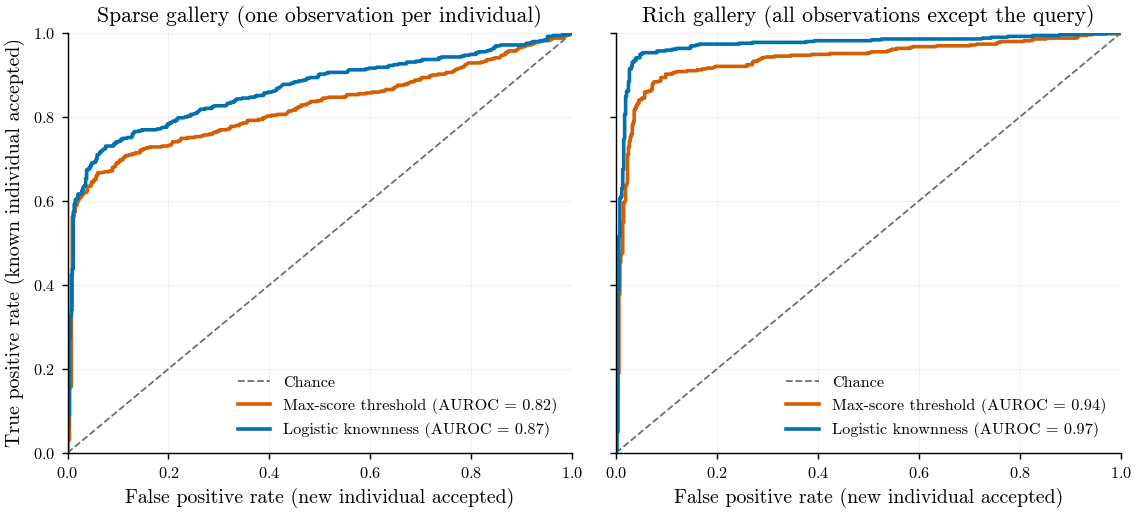

In [50]:
COLORS = dict(zip(["blue", "vermillion", "green", "purple", "orange", "sky", "yellow", "gray"],
                  PALETTE))


def save_figure(figure, name):
    """Write the figure as PDF, for LaTeX, and as PNG, for a quick look."""
    figure.tight_layout(pad=1.2)
    figure.savefig(FIGURE_DIR / f"{name}.pdf")
    figure.savefig(FIGURE_DIR / f"{name}.png", dpi=200)
    print(f"wrote {FIGURE_DIR / name}.pdf and .png")


figure, axes = plt.subplots(1, 2, figsize=(9.0, 4.2), sharex=True, sharey=True)
for axis, policy in zip(axes, GALLERY_POLICIES):
    axis.plot([0, 1], [0, 1], linestyle="--", color=COLORS["gray"], linewidth=1.0, label="Chance")
    for method, name, color in [(METHODS[4], "Max-score threshold", COLORS["vermillion"]),
                                (METHODS[5], "Logistic knownness", COLORS["blue"])]:
        # The first gallery draw only: pooling every draw would repeat each query.
        row = results[policy][method][0]
        known, unknown = row["known_scores"], row["unknown_scores"]
        truth = np.r_[np.ones(len(known)), np.zeros(len(unknown))]
        scores = np.r_[known, unknown]
        false_positive, true_positive, _ = roc_curve(truth, scores)
        axis.plot(false_positive, true_positive, linewidth=2.0, color=color,
                  label=f"{name} (AUROC = {roc_auc_score(truth, scores):.2f})")
    axis.set_xlabel("False positive rate (new individual accepted)")
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1)
    axis.legend(loc="lower right")
    axis.set_title(GALLERY_POLICIES[policy])
axes[0].set_ylabel("True positive rate (known individual accepted)")
save_figure(figure, "reid_open_set_decision")
plt.show()

### Figure 3 — What relevance weighting keeps

**Caption.** Example images of high relevance (upper row) versus low relevance (lower row). Images automatically classified as high relevance images are usually side view images of the head with good illumination.


wrote /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/outputs/figures/reid_relevance_examples.pdf and .png


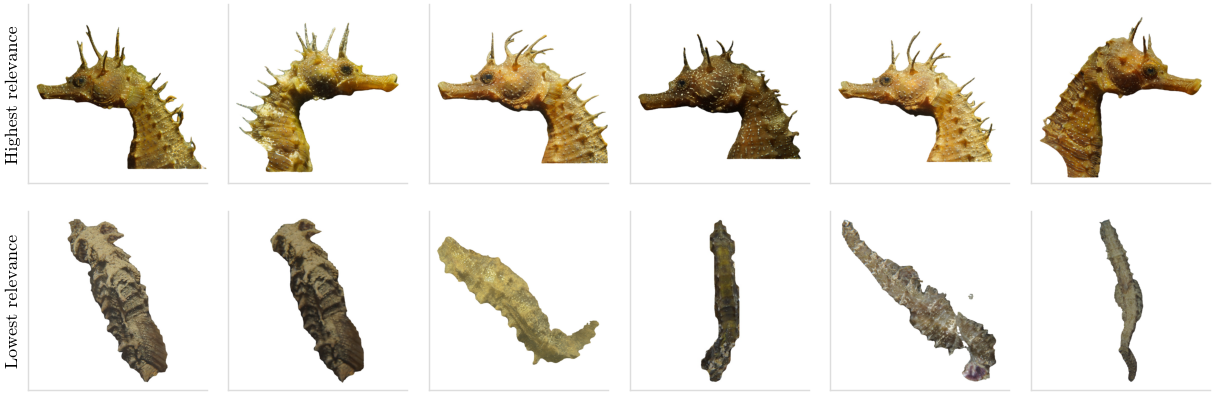

relevance over 6118 test photographs: median 0.50, 0% floored at 0.02


In [51]:
N_EXAMPLES = 6

# The test queries, weighted by the relevance model of the first sparse draw: photographs the
# model has never seen. No weight is printed: the ranking says more than the weights do.
ranked = relevance_test.sort_values("relevance", ascending=False)
figure, axes = plt.subplots(2, N_EXAMPLES, figsize=(1.6 * N_EXAMPLES, 3.4))
for (label, tiles), axis_row in zip([("Highest relevance", ranked.head(N_EXAMPLES)),
                                     ("Lowest relevance", ranked.tail(N_EXAMPLES).iloc[::-1])], axes):
    for axis, (_, tile) in zip(axis_row, tiles.iterrows()):
        image = Image.open(SEGMENTED_COMPRESSED / tile["name"]).convert("RGB")
        # Centre the crop on a white square, so no view is stretched. White matches the background
        # that the segmentation paints, exactly (255, 255, 255).
        image = ImageOps.pad(image, (max(image.size),) * 2, color=(255, 255, 255))
        image.thumbnail((512, 512))  # so the PDF does not carry six 2048 px photographs
        axis.imshow(image)
        # No ticks, no grid, a light frame.
        axis.set_xticks([])
        axis.set_yticks([])
        axis.grid(False)
        for spine in axis.spines.values():
            spine.set_color("#DDDDDD")
    axis_row[0].set_ylabel(label, fontsize=10)
figure.subplots_adjust(wspace=0.02, hspace=0.05)
save_figure(figure, "reid_relevance_examples")
plt.show()

print(f"relevance over {len(relevance_test)} test photographs: "
      f"median {relevance_test['relevance'].median():.2f}, "
      f"{(relevance_test['relevance'] < RELEVANCE_FLOOR).mean():.0%} floored at {RELEVANCE_FLOOR}")

### Figure — Local matches kept and rejected by the RANSAC check

The ALIKED/LightGlue matches of four test pairs: two pairs of one individual seen in two
observations, and two pairs of two individuals. The matches that agree with the published
fundamental matrix are green; the ones it rejects are orange.

**Caption.** ALIKED/LightGlue correspondences image pairs from the test split, before and after geometric verification. Green lines join the correspondences that agree with the fundamental matrix fitted by RANSAC, and vermillion lines join the ones it rejects.


SH052_001_002_det0_cropped.jpg::SH052_003_004_det0_cropped.jpg: 73 of 89 matches agree with the fundamental matrix (cache: 73.0)


SH373_001_010_det0_cropped.jpg::SH373_008_002_det0_cropped.jpg: 53 of 69 matches agree with the fundamental matrix (cache: 53.0)


SH349_021_013_det0_cropped.jpg::SH427_007_016_det0_cropped.jpg: 29 of 62 matches agree with the fundamental matrix (cache: 29.0)


SH298_003_009_det0_cropped.jpg::SH401_008_006_det0_cropped.jpg: 22 of 47 matches agree with the fundamental matrix (cache: 22.0)


wrote /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/outputs/figures/reid_local_matches.pdf and .png


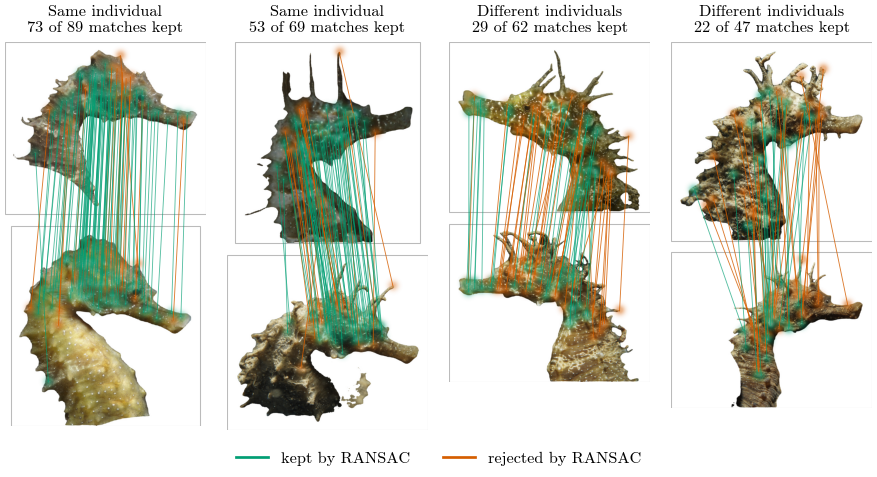

In [52]:
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter

MATCH_PAIRS = [
    "SH052_001_002_det0_cropped.jpg::SH052_003_004_det0_cropped.jpg",  # colour change
    "SH373_001_010_det0_cropped.jpg::SH373_008_002_det0_cropped.jpg",  # head turned
    "SH349_021_013_det0_cropped.jpg::SH427_007_016_det0_cropped.jpg",  # two individuals
    "SH298_003_009_det0_cropped.jpg::SH401_008_006_det0_cropped.jpg",  # two individuals
]
DISPLAY_SIDE = 1024  # drawn resolution; the keypoints live in the matcher's 512 px frame
GAP = 60             # pixels between the two photographs of a pair
GLOW_SIGMA = DISPLAY_SIDE / 70
INLIER, OUTLIER = COLORS["green"], COLORS["vermillion"]

extract_features(MATCHING, sorted({name for pair in MATCH_PAIRS for name in pair.split("::")}))
figure, axes = plt.subplots(1, len(MATCH_PAIRS), figsize=(1.75 * len(MATCH_PAIRS), 3.9), squeeze=False)
for axis, pair in zip(axes[0], MATCH_PAIRS):
    first, second = pair.split("::")
    points0, points1 = lightglue_matches(MATCHING, first, second)
    # Which matches agree with the published fundamental matrix.
    if len(points0) < MIN_RANSAC_POINTS:
        mask = np.zeros(len(points0), dtype=bool)
    else:
        cv2.setRNGSeed(SEED)
        _, ransac_mask = cv2.findFundamentalMat(points0.astype(np.float64), points1.astype(np.float64),
                                                cv2.FM_RANSAC, RANSAC_THRESHOLD, RANSAC_CONFIDENCE,
                                                RANSAC_ITERATIONS)
        mask = np.zeros(len(points0), dtype=bool) if ransac_mask is None else ransac_mask.ravel().astype(bool)

    # Each crop at DISPLAY_SIDE, and its matches scaled from matcher pixels to displayed pixels.
    pair_images, points, offsets = [], [], []
    for name, matched in zip(pair.split("::"), (points0, points1)):
        image = Image.open(SEGMENTED_COMPRESSED / name).convert("RGB")
        longest = max(image.size)
        scale = DISPLAY_SIDE / longest
        image = image.resize((round(image.width * scale), round(image.height * scale)))
        pair_images.append(np.asarray(image) / 255.0)
        points.append(matched * (DISPLAY_SIDE / min(longest, MAX_IMAGE_SIDE)))

    # Stack the two photographs and draw the matches.
    width, top = max(image.shape[1] for image in pair_images), 0.0
    for image in pair_images:
        offsets.append(((width - image.shape[1]) / 2, top))
        top += image.shape[0] + GAP
    for image, matched, (left, upper) in zip(pair_images, points, offsets):
        height, image_width = image.shape[:2]
        extent = (left, left + image_width, upper + height, upper)
        # Slightly desaturated, so the coloured lines and glows stand out from the animal.
        axis.imshow(0.7 * image + 0.3 * image.mean(axis=2, keepdims=True), extent=extent)
        for keep, color in [(~mask, OUTLIER), (mask, INLIER)]:
            # A glow: a blurred density of the points, transparent where there are none.
            density = np.zeros(image.shape[:2])
            columns = np.clip(np.round(matched[keep][:, 0]).astype(int), 0, image.shape[1] - 1)
            rows = np.clip(np.round(matched[keep][:, 1]).astype(int), 0, image.shape[0] - 1)
            np.add.at(density, (rows, columns), 1.0)
            density = gaussian_filter(density, GLOW_SIGMA)
            if density.max() > 0:
                density = (density / density.max()) ** 0.7
            rgb = np.array(to_rgb(color))
            glow = LinearSegmentedColormap.from_list(
                "glow", [(*rgb, 0.0), (*rgb, 0.45), (*(0.4 + 0.6 * rgb), 0.75)])(density)
            axis.imshow(glow, extent=extent)
        axis.add_patch(Rectangle((left, upper), image_width, height, fill=False,
                                 edgecolor="#BBBBBB", linewidth=0.6))
    (left0, upper0), (left1, upper1) = offsets
    for keep, color, alpha in [(~mask, OUTLIER, 0.8), (mask, INLIER, 0.65)]:
        for (x0, y0), (x1, y1) in zip(points[0][keep], points[1][keep]):
            axis.plot([x0 + left0, x1 + left1], [y0 + upper0, y1 + upper1], color=color,
                      linewidth=0.5, alpha=alpha, solid_capstyle="round")
    axis.set_xlim(0, width)
    axis.set_ylim(top - GAP, 0)
    axis.set_axis_off()
    axis.set_anchor("N")  # panels of different heights line up at the top
    inliers, total = int(mask.sum()), len(mask)
    label = "Same individual" if first[:5] == second[:5] else "Different individuals"
    axis.set_title(f"{label}\n{inliers} of {total} matches kept", fontsize=9)
    print(f"{pair}: {inliers} of {total} matches agree with the fundamental matrix "
          f"(cache: {MATCHING['cache']['f4'].get(pair)})")
figure.legend(handles=[Line2D([], [], color=INLIER, linewidth=1.5, label="kept by RANSAC"),
                       Line2D([], [], color=OUTLIER, linewidth=1.5, label="rejected by RANSAC")],
              loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.02))
figure.subplots_adjust(wspace=0.05)
save_figure(figure, "reid_local_matches")
plt.show()